In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/26__walking_down_street_outside_angry.mp4
/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/08__talking_against_wall.mp4
/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/14__walking_down_indoor_hall_disgust.mp4
/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/08__walking_down_street_outside_angry.mp4
/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/05__outside_talking_still_laughing.mp4
/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/14__exit_phone_room.mp4
/kaggle/input/datasets/sanikatiwarekar/deep-fake-detection-dfd-entire-original-dataset/DFD_original sequences/06__walk_down

In [2]:
# ============================================================
# STEP 10.13.1 — CREATE 720-VIDEO MANIFEST
# 360 REAL + 360 FAKE
# ============================================================

from pathlib import Path
import random
import pandas as pd

# ------------------------------------------------------------
# 1. SOURCE DATASET
# ------------------------------------------------------------

DATASET_ROOT = Path(
    "/kaggle/input/datasets/sanikatiwarekar/"
    "deep-fake-detection-dfd-entire-original-dataset"
)

# ------------------------------------------------------------
# 2. NEW EXPERIMENT DIRECTORY
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/kaggle/working/deepfake_authentication_720"
)

MANIFEST_DIR = PROJECT_DIR / "manifests"

MANIFEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. VIDEO DIRECTORIES
# ------------------------------------------------------------

REAL_DIR = (
    DATASET_ROOT /
    "DFD_original sequences"
)

FAKE_DIR = (
    DATASET_ROOT /
    "DFD_manipulated_sequences" /
    "DFD_manipulated_sequences"
)

# ------------------------------------------------------------
# 4. COLLECT ALL VIDEOS
# ------------------------------------------------------------

real_videos = sorted(
    REAL_DIR.glob("*.mp4")
)

fake_videos = sorted(
    FAKE_DIR.glob("*.mp4")
)

print("=" * 60)
print("AVAILABLE VIDEOS")
print("=" * 60)

print(
    f"REAL videos available: {len(real_videos)}"
)

print(
    f"FAKE videos available: {len(fake_videos)}"
)

# ------------------------------------------------------------
# 5. TARGET COUNTS
# ------------------------------------------------------------

TARGET_REAL = 360
TARGET_FAKE = 360

if len(real_videos) < TARGET_REAL:
    raise ValueError(
        f"Not enough REAL videos. "
        f"Required: {TARGET_REAL}, "
        f"Available: {len(real_videos)}"
    )

if len(fake_videos) < TARGET_FAKE:
    raise ValueError(
        f"Not enough FAKE videos. "
        f"Required: {TARGET_FAKE}, "
        f"Available: {len(fake_videos)}"
    )

# ------------------------------------------------------------
# 6. DETERMINISTIC SAMPLING
# ------------------------------------------------------------

random.seed(42)

selected_real = random.sample(
    real_videos,
    TARGET_REAL
)

random.seed(42)

selected_fake = random.sample(
    fake_videos,
    TARGET_FAKE
)

# ------------------------------------------------------------
# 7. BUILD MANIFEST
# ------------------------------------------------------------

records = []

for video_path in selected_real:

    records.append({
        "video_path": str(video_path),
        "label": 0,
        "label_name": "REAL"
    })

for video_path in selected_fake:

    records.append({
        "video_path": str(video_path),
        "label": 1,
        "label_name": "FAKE"
    })

manifest = pd.DataFrame(records)

# Shuffle deterministically
manifest = manifest.sample(
    frac=1.0,
    random_state=42
).reset_index(drop=True)

# Add unique video ID
manifest.insert(
    0,
    "video_id",
    range(len(manifest))
)

# ------------------------------------------------------------
# 8. SAVE MANIFEST
# ------------------------------------------------------------

MANIFEST_PATH = (
    MANIFEST_DIR /
    "video_manifest_720.csv"
)

manifest.to_csv(
    MANIFEST_PATH,
    index=False
)

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

real_count = (
    manifest["label_name"] == "REAL"
).sum()

fake_count = (
    manifest["label_name"] == "FAKE"
).sum()

print("\n" + "=" * 60)
print("720-VIDEO MANIFEST CREATED")
print("=" * 60)

print(f"REAL selected:  {real_count}")
print(f"FAKE selected:  {fake_count}")
print(f"TOTAL selected: {len(manifest)}")

print(
    f"\nManifest saved to:\n"
    f"{MANIFEST_PATH}"
)

assert len(manifest) == 720
assert real_count == 360
assert fake_count == 360

print("\n✓ Manifest validation passed")
print("✓ 360 REAL + 360 FAKE")
print("✓ Previous 40 videos may be included")
print("✓ Manifest is persisted to disk")

AVAILABLE VIDEOS
REAL videos available: 363
FAKE videos available: 3068

720-VIDEO MANIFEST CREATED
REAL selected:  360
FAKE selected:  360
TOTAL selected: 720

Manifest saved to:
/kaggle/working/deepfake_authentication_720/manifests/video_manifest_720.csv

✓ Manifest validation passed
✓ 360 REAL + 360 FAKE
✓ Previous 40 videos may be included
✓ Manifest is persisted to disk


In [3]:
# ============================================================
# STEP 10.13.2 — VIDEO-LEVEL TRAIN / VALIDATION SPLIT
# ============================================================

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/kaggle/working/deepfake_authentication_720"
)

MANIFEST_PATH = (
    PROJECT_DIR /
    "manifests" /
    "video_manifest_720.csv"
)

SPLIT_PATH = (
    PROJECT_DIR /
    "manifests" /
    "video_split_720.csv"
)

# ------------------------------------------------------------
# Load manifest
# ------------------------------------------------------------

manifest = pd.read_csv(
    MANIFEST_PATH
)

print(
    f"Loaded videos: {len(manifest)}"
)

# ------------------------------------------------------------
# Stratified video-level split
# ------------------------------------------------------------

train_df, val_df = train_test_split(
    manifest,
    test_size=0.20,
    random_state=42,
    stratify=manifest["label"]
)

# ------------------------------------------------------------
# Add split column
# ------------------------------------------------------------

train_df = train_df.copy()
val_df = val_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"

split_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Keep deterministic ordering
split_df = split_df.sort_values(
    "video_id"
).reset_index(drop=True)

# ------------------------------------------------------------
# Save split
# ------------------------------------------------------------

split_df.to_csv(
    SPLIT_PATH,
    index=False
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

train_real = (
    train_df["label_name"] == "REAL"
).sum()

train_fake = (
    train_df["label_name"] == "FAKE"
).sum()

val_real = (
    val_df["label_name"] == "REAL"
).sum()

val_fake = (
    val_df["label_name"] == "FAKE"
).sum()

# ------------------------------------------------------------
# Check overlap
# ------------------------------------------------------------

train_ids = set(
    train_df["video_id"]
)

val_ids = set(
    val_df["video_id"]
)

overlap = train_ids.intersection(
    val_ids
)

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("VIDEO-LEVEL TRAIN / VALIDATION SPLIT")
print("=" * 60)

print("\nTRAIN")
print(f"REAL:  {train_real}")
print(f"FAKE:  {train_fake}")
print(f"TOTAL: {len(train_df)}")

print("\nVALIDATION")
print(f"REAL:  {val_real}")
print(f"FAKE:  {val_fake}")
print(f"TOTAL: {len(val_df)}")

print(
    f"\nTrain/Validation overlap: "
    f"{len(overlap)}"
)

print(
    f"\nSplit manifest saved to:\n"
    f"{SPLIT_PATH}"
)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert len(train_df) == 576
assert len(val_df) == 144

assert train_real == 288
assert train_fake == 288

assert val_real == 72
assert val_fake == 72

assert len(overlap) == 0

print("\n✓ Split validation passed")
print("✓ No video overlap")
print("✓ 80/20 stratified split")
print("✓ Split persisted to disk")

Loaded videos: 720

VIDEO-LEVEL TRAIN / VALIDATION SPLIT

TRAIN
REAL:  288
FAKE:  288
TOTAL: 576

VALIDATION
REAL:  72
FAKE:  72
TOTAL: 144

Train/Validation overlap: 0

Split manifest saved to:
/kaggle/working/deepfake_authentication_720/manifests/video_split_720.csv

✓ Split validation passed
✓ No video overlap
✓ 80/20 stratified split
✓ Split persisted to disk


In [4]:
# ============================================================
# STEP 10.13.3 — SAMPLE 16 FRAMES PER VIDEO
# ============================================================

import cv2
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/kaggle/working/deepfake_authentication_720"
)

MANIFEST_PATH = (
    PROJECT_DIR /
    "manifests" /
    "video_split_720.csv"
)

FRAMES_DIR = (
    PROJECT_DIR /
    "frames_720"
)

FRAMES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

NUM_FRAMES = 16

# ------------------------------------------------------------
# Load split manifest
# ------------------------------------------------------------

split_df = pd.read_csv(
    MANIFEST_PATH
)

print(
    f"Videos to process: {len(split_df)}"
)

# ------------------------------------------------------------
# Frame sampling function
# ------------------------------------------------------------

def sample_video_frames(
    video_path,
    output_dir,
    num_frames=16
):
    """
    Uniformly sample frames from a video.
    """

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Resume-safe:
    # If all expected frames exist, skip video.
    existing_frames = sorted(
        output_dir.glob("frame_*.jpg")
    )

    if len(existing_frames) == num_frames:
        return "skipped"

    # Remove incomplete previous output
    for frame_file in existing_frames:
        frame_file.unlink()

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        return "failed"

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if total_frames <= 0:
        cap.release()
        return "failed"

    # Uniformly spaced frame indices
    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    saved_count = 0

    for output_index, frame_index in enumerate(
        frame_indices
    ):

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_index)
        )

        success, frame = cap.read()

        if not success or frame is None:
            continue

        output_path = (
            output_dir /
            f"frame_{output_index:02d}.jpg"
        )

        cv2.imwrite(
            str(output_path),
            frame
        )

        saved_count += 1

    cap.release()

    if saved_count == num_frames:
        return "processed"

    # Incomplete output should not be treated as valid
    for frame_file in output_dir.glob(
        "frame_*.jpg"
    ):
        frame_file.unlink()

    return "failed"


# ------------------------------------------------------------
# Process all videos
# ------------------------------------------------------------

processed = 0
skipped = 0
failed = 0

for index, row in split_df.iterrows():

    video_path = Path(
        row["video_path"]
    )

    label_name = row["label_name"]

    video_id = int(
        row["video_id"]
    )

    output_dir = (
        FRAMES_DIR /
        label_name /
        f"video_{video_id:04d}"
    )

    status = sample_video_frames(
        video_path,
        output_dir,
        NUM_FRAMES
    )

    if status == "processed":
        processed += 1

    elif status == "skipped":
        skipped += 1

    else:
        failed += 1
        print(
            f"FAILED: {video_path}"
        )

    # Progress
    if (
        (index + 1) % 50 == 0
        or index == len(split_df) - 1
    ):

        print(
            f"Progress: "
            f"{index + 1}/{len(split_df)} | "
            f"Processed: {processed} | "
            f"Skipped: {skipped} | "
            f"Failed: {failed}"
        )

# ------------------------------------------------------------
# Final result
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FRAME SAMPLING COMPLETE")
print("=" * 60)

print(f"Processed videos: {processed}")
print(f"Skipped videos:   {skipped}")
print(f"Failed videos:    {failed}")

print(
    f"Expected frames: "
    f"{len(split_df) * NUM_FRAMES}"
)

print(
    f"\nOutput directory:\n"
    f"{FRAMES_DIR}"
)

if failed == 0:
    print("\n✓ FRAME SAMPLING SUCCESSFUL")
else:
    print(
        "\n⚠ Some videos failed. "
        "We will inspect them before continuing."
    )

Videos to process: 720
Progress: 50/720 | Processed: 0 | Skipped: 50 | Failed: 0
Progress: 100/720 | Processed: 0 | Skipped: 100 | Failed: 0
Progress: 150/720 | Processed: 0 | Skipped: 150 | Failed: 0
Progress: 200/720 | Processed: 0 | Skipped: 200 | Failed: 0
Progress: 250/720 | Processed: 0 | Skipped: 250 | Failed: 0
Progress: 300/720 | Processed: 0 | Skipped: 300 | Failed: 0
Progress: 350/720 | Processed: 0 | Skipped: 350 | Failed: 0
Progress: 400/720 | Processed: 0 | Skipped: 400 | Failed: 0
Progress: 450/720 | Processed: 0 | Skipped: 450 | Failed: 0
Progress: 500/720 | Processed: 0 | Skipped: 500 | Failed: 0
Progress: 550/720 | Processed: 0 | Skipped: 550 | Failed: 0
Progress: 600/720 | Processed: 0 | Skipped: 600 | Failed: 0
Progress: 650/720 | Processed: 50 | Skipped: 600 | Failed: 0
Progress: 700/720 | Processed: 100 | Skipped: 600 | Failed: 0
Progress: 720/720 | Processed: 120 | Skipped: 600 | Failed: 0

FRAME SAMPLING COMPLETE
Processed videos: 120
Skipped videos:   600
Faile

In [5]:
from pathlib import Path
import cv2
import pandas as pd

PROJECT_DIR = Path(
    "/kaggle/working/deepfake_authentication_720"
)

FRAMES_DIR = PROJECT_DIR / "frames_720"

SPLIT_PATH = (
    PROJECT_DIR / "manifests" / "video_split_720.csv"
)

split_df = pd.read_csv(SPLIT_PATH)

expected_frames = 16
total_frames = 0
bad_videos = []
unreadable_frames = []

for _, row in split_df.iterrows():
    label_name = row["label_name"]
    video_id = int(row["video_id"])

    video_dir = (
        FRAMES_DIR /
        label_name /
        f"video_{video_id:04d}"
    )

    frame_paths = sorted(
        video_dir.glob("frame_*.jpg")
    ) if video_dir.exists() else []

    if len(frame_paths) != expected_frames:
        bad_videos.append({
            "video_id": video_id,
            "label": label_name,
            "frame_count": len(frame_paths)
        })
        continue

    for frame_path in frame_paths:
        image = cv2.imread(str(frame_path))

        if image is None:
            unreadable_frames.append(str(frame_path))

    total_frames += len(frame_paths)

print("=" * 60)
print("FRAME INTEGRITY REPORT")
print("=" * 60)

print("Videos in split:", len(split_df))
print("Frames in correctly sized directories:", total_frames)
print("Videos with incorrect frame counts:", len(bad_videos))
print("Unreadable frame files:", len(unreadable_frames))

if bad_videos:
    print("\nFirst problematic videos:")
    print(pd.DataFrame(bad_videos).head(10))

if unreadable_frames:
    print("\nFirst unreadable files:")
    print(unreadable_frames[:10])

if not bad_videos and not unreadable_frames:
    assert len(split_df) == 720
    assert total_frames == 11520

    print("\nSUCCESS: All 720 videos have 16 readable frames.")
else:
    print("\nSome files need repair before proceeding.")

FRAME INTEGRITY REPORT
Videos in split: 720
Frames in correctly sized directories: 11520
Videos with incorrect frame counts: 0
Unreadable frame files: 0

SUCCESS: All 720 videos have 16 readable frames.


In [6]:
import torch
import cv2
import numpy as np
from pathlib import Path
from PIL import Image
import time
import json

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [7]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("facenet_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "facenet-pytorch", "--no-deps", "-q"
    ])

from facenet_pytorch import MTCNN

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

mtcnn = MTCNN(
    image_size=224,
    margin=20,
    keep_all=True,
    post_process=False,
    device=DEVICE
)

print("MTCNN initialized successfully.")
print("Device:", DEVICE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 23.0 MB/s eta 0:00:00
MTCNN initialized successfully.
Device: cuda


In [8]:
import time

PROJECT_DIR = Path(
    "/kaggle/working/deepfake_authentication_720"
)

FRAMES_DIR = PROJECT_DIR / "frames_720"

sample_frames = sorted(
    FRAMES_DIR.rglob("frame_*.jpg")
)[:32]

if not sample_frames:
    raise FileNotFoundError(
        f"No sampled frames found in {FRAMES_DIR}"
    )

start_time = time.time()
successful = 0

for frame_path in sample_frames:
    frame = cv2.imread(str(frame_path))

    if frame is None:
        continue

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    boxes, probabilities = mtcnn.detect(rgb)
    successful += 1

elapsed = time.time() - start_time

print("=" * 50)
print("MTCNN BENCHMARK")
print("=" * 50)
print("Frames tested:", len(sample_frames))
print("Frames read:", successful)
print(f"Time: {elapsed:.2f} seconds")
print(f"Throughput: {successful / elapsed:.2f} frames/sec")

if successful:
    estimated_minutes = 11520 / (successful / elapsed) / 60
    print(
        f"Rough estimate for 11,520 frames: "
        f"{estimated_minutes:.1f} minutes"
    )

MTCNN BENCHMARK
Frames tested: 32
Frames read: 32
Time: 4.76 seconds
Throughput: 6.72 frames/sec
Rough estimate for 11,520 frames: 28.6 minutes


In [11]:
from pathlib import Path
import cv2
import json
import time
import numpy as np

PROJECT_DIR = Path(
    "/kaggle/working/deepfake_authentication_720"
)

FRAMES_DIR = PROJECT_DIR / "frames_720"
FACES_DIR = PROJECT_DIR / "faces_720"
METADATA_DIR = PROJECT_DIR / "metadata_720"

FACES_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

def detect_all_faces(frame, detector):
    """
    Detect and crop all faces from a BGR frame.
    Returns face images and detection metadata.
    """
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    boxes, probabilities = detector.detect(rgb)

    if boxes is None:
        return [], []

    # Explicitly convert detector outputs to numeric arrays.
    boxes = np.asarray(boxes, dtype=np.float64)

    if probabilities is None:
        probabilities = np.full(len(boxes), np.nan)
    else:
        probabilities = np.asarray(
            probabilities, dtype=np.float64
        )

    height, width = frame.shape[:2]
    faces = []
    detections = []

    for box, probability in zip(boxes, probabilities):
        if box.shape != (4,) or not np.isfinite(box).all():
            continue

        if not np.isfinite(probability):
            continue

        x1, y1, x2, y2 = np.round(box).astype(int)

        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(width, x2)
        y2 = min(height, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        face = frame[y1:y2, x1:x2]

        if face.size == 0:
            continue

        face = cv2.resize(
            face,
            (224, 224),
            interpolation=cv2.INTER_AREA
        )

        faces.append(face)

        detections.append({
            "box": [int(x1), int(y1), int(x2), int(y2)],
            "probability": float(probability)
        })

    return faces, detections

def extract_faces_for_frame(frame_path, output_dir, detector):
    """
    Resume-safe at the individual-frame level.
    A marker is written only after all face files and metadata are saved.
    """
    output_dir.mkdir(parents=True, exist_ok=True)

    marker = output_dir / "_complete.json"

    if marker.exists():
        try:
            saved = json.loads(marker.read_text())
            expected_count = saved["face_count"]
            face_files = list(output_dir.glob("face_*.jpg"))

            if len(face_files) == expected_count:
                return "skipped", expected_count
        except (ValueError, KeyError, OSError):
            pass

    # Remove incomplete outputs before retrying this frame.
    for path in output_dir.glob("face_*.jpg"):
        path.unlink()

    marker.unlink(missing_ok=True)

    frame = cv2.imread(str(frame_path))

    if frame is None:
        return "failed", 0

    faces, detections = detect_all_faces(frame, detector)

    for i, face in enumerate(faces):
        face_path = output_dir / f"face_{i:02d}.jpg"

        if not cv2.imwrite(str(face_path), face):
            raise OSError(f"Could not save face: {face_path}")

    metadata_path = output_dir / "detections.json"
    metadata_path.write_text(
        json.dumps(detections, indent=2)
    )

    marker.write_text(json.dumps({
        "source_frame": str(frame_path),
        "face_count": len(faces),
        "status": "complete"
    }))

    return "processed", len(faces)


print("Face extraction functions ready.")
print("Input:", FRAMES_DIR)
print("Faces:", FACES_DIR)

Face extraction functions ready.
Input: /kaggle/working/deepfake_authentication_720/frames_720
Faces: /kaggle/working/deepfake_authentication_720/faces_720


In [12]:
import time
import pandas as pd

SPLIT_PATH = (
    PROJECT_DIR / "manifests" / "video_split_720.csv"
)

split_df = pd.read_csv(SPLIT_PATH)

processed = 0
skipped = 0
failed = 0
total_faces = 0
start_time = time.time()

frame_paths = sorted(FRAMES_DIR.rglob("frame_*.jpg"))

print("Frames found:", len(frame_paths))

for index, frame_path in enumerate(frame_paths, start=1):
    # Expected layout: frames_720/LABEL/video_ID/frame_XX.jpg
    label_name = frame_path.parent.parent.name
    video_name = frame_path.parent.name

    output_dir = (
        FACES_DIR / label_name / video_name / frame_path.stem
    )

    try:
        status, face_count = extract_faces_for_frame(
            frame_path,
            output_dir,
            mtcnn
        )

        total_faces += face_count

        if status == "processed":
            processed += 1
        elif status == "skipped":
            skipped += 1
        else:
            failed += 1
            print("Unreadable frame:", frame_path)

    except Exception as exc:
        failed += 1
        print(f"ERROR: {frame_path} | {exc}")

    if index % 100 == 0 or index == len(frame_paths):
        elapsed = time.time() - start_time
        rate = index / elapsed if elapsed else 0

        print(
            f"{index}/{len(frame_paths)} | "
            f"Processed: {processed} | "
            f"Skipped: {skipped} | "
            f"Failed: {failed} | "
            f"Faces this run: {total_faces} | "
            f"Rate: {rate:.2f} frames/sec"
        )

elapsed = time.time() - start_time

print("\n" + "=" * 60)
print("FACE EXTRACTION RUN FINISHED")
print("=" * 60)
print("Processed frames:", processed)
print("Skipped frames:", skipped)
print("Failed frames:", failed)
print("Faces detected during this run:", total_faces)
print(f"Elapsed time: {elapsed / 60:.1f} minutes")
print("Output:", FACES_DIR)

Frames found: 11520
100/11520 | Processed: 98 | Skipped: 2 | Failed: 0 | Faces this run: 129 | Rate: 9.48 frames/sec
200/11520 | Processed: 196 | Skipped: 4 | Failed: 0 | Faces this run: 266 | Rate: 9.94 frames/sec
300/11520 | Processed: 296 | Skipped: 4 | Failed: 0 | Faces this run: 405 | Rate: 10.27 frames/sec
400/11520 | Processed: 396 | Skipped: 4 | Failed: 0 | Faces this run: 570 | Rate: 10.49 frames/sec
500/11520 | Processed: 496 | Skipped: 4 | Failed: 0 | Faces this run: 726 | Rate: 10.46 frames/sec
600/11520 | Processed: 596 | Skipped: 4 | Failed: 0 | Faces this run: 852 | Rate: 10.42 frames/sec
700/11520 | Processed: 696 | Skipped: 4 | Failed: 0 | Faces this run: 992 | Rate: 10.33 frames/sec
800/11520 | Processed: 796 | Skipped: 4 | Failed: 0 | Faces this run: 1123 | Rate: 10.38 frames/sec
900/11520 | Processed: 896 | Skipped: 4 | Failed: 0 | Faces this run: 1267 | Rate: 10.17 frames/sec
1000/11520 | Processed: 996 | Skipped: 4 | Failed: 0 | Faces this run: 1376 | Rate: 10.13 

In [13]:

from pathlib import Path
import json
import cv2
import pandas as pd

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FRAMES_DIR = PROJECT_DIR / "frames_720"
FACES_DIR = PROJECT_DIR / "faces_720"

frame_paths = sorted(FRAMES_DIR.rglob("frame_*.jpg"))

checked = 0
frames_with_faces = 0
frames_without_faces = 0
total_saved_faces = 0

missing_markers = []
missing_metadata = []
count_mismatches = []
unreadable_faces = []
invalid_metadata = []

for frame_path in frame_paths:
    label = frame_path.parent.parent.name
    video = frame_path.parent.name
    frame_name = frame_path.stem

    output_dir = FACES_DIR / label / video / frame_name
    marker_path = output_dir / "_complete.json"
    metadata_path = output_dir / "detections.json"

    checked += 1

    if not marker_path.exists():
        missing_markers.append(str(marker_path))
        continue

    if not metadata_path.exists():
        missing_metadata.append(str(metadata_path))
        continue

    try:
        marker = json.loads(marker_path.read_text())
        detections = json.loads(metadata_path.read_text())

        expected_count = int(marker["face_count"])
        face_files = sorted(output_dir.glob("face_*.jpg"))

        if len(face_files) != expected_count or len(detections) != expected_count:
            count_mismatches.append({
                "frame": str(frame_path),
                "marker_count": expected_count,
                "face_files": len(face_files),
                "metadata_count": len(detections)
            })
            continue

        if marker.get("status") != "complete":
            invalid_metadata.append(str(marker_path))
            continue

        bad_faces = []
        for face_path in face_files:
            image = cv2.imread(str(face_path))
            if image is None:
                bad_faces.append(str(face_path))

        if bad_faces:
            unreadable_faces.extend(bad_faces)
            continue

        total_saved_faces += expected_count

        if expected_count > 0:
            frames_with_faces += 1
        else:
            frames_without_faces += 1

    except Exception as exc:
        invalid_metadata.append(f"{metadata_path}: {exc}")

print("=" * 60)
print("FACE EXTRACTION VALIDATION")
print("=" * 60)
print("Frames discovered:", len(frame_paths))
print("Frames checked:", checked)
print("Frames with faces:", frames_with_faces)
print("Frames without faces:", frames_without_faces)
print("Total saved faces:", total_saved_faces)
print("Missing completion markers:", len(missing_markers))
print("Missing metadata files:", len(missing_metadata))
print("Face-count mismatches:", len(count_mismatches))
print("Unreadable face images:", len(unreadable_faces))
print("Invalid metadata/markers:", len(invalid_metadata))

if (
    len(frame_paths) == 11520
    and not missing_markers
    and not missing_metadata
    and not count_mismatches
    and not unreadable_faces
    and not invalid_metadata
):
    print("\nSUCCESS: Face extraction artifacts passed validation.")
else:
    print("\nWARNING: Review the validation issues before continuing.")

FACE EXTRACTION VALIDATION
Frames discovered: 11520
Frames checked: 11520
Frames with faces: 11350
Frames without faces: 170
Total saved faces: 15250
Missing completion markers: 0
Missing metadata files: 0
Face-count mismatches: 0
Unreadable face images: 0
Invalid metadata/markers: 0

SUCCESS: Face extraction artifacts passed validation.


In [14]:

%pip install -q open_clip_torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [15]:

import torch
import cv2
import numpy as np
from pathlib import Path

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable; embedding extraction will be slower.")

try:
    import open_clip
    print("open_clip: available")
except ImportError:
    print("open_clip: not installed")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
open_clip: available


In [16]:

import torch
import open_clip

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FACES_DIR = PROJECT_DIR / "faces_720"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"

EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vit_model, _, vit_preprocess = open_clip.create_model_and_transforms(
    "ViT-L-14",
    pretrained="openai"
)

vit_model = vit_model.to(device)
vit_model.eval()

for parameter in vit_model.parameters():
    parameter.requires_grad = False

print("Device:", device)
print("Model: ViT-L/14")
print("Trainable parameters:", sum(
    p.numel() for p in vit_model.parameters() if p.requires_grad
))
print("Embedding dimension:", vit_model.visual.output_dim)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Device: cuda
Model: ViT-L/14
Trainable parameters: 0
Embedding dimension: 768


In [17]:

from PIL import Image
import torch.nn.functional as F

sample_faces = sorted(FACES_DIR.rglob("face_*.jpg"))

assert len(sample_faces) > 0, "No face crops found."

sample_image = Image.open(sample_faces[0]).convert("RGB")
sample_tensor = vit_preprocess(sample_image).unsqueeze(0).to(device)

with torch.inference_mode():
    sample_embedding = vit_model.encode_image(sample_tensor)
    sample_embedding = F.normalize(sample_embedding.float(), dim=-1)

print("Sample face:", sample_faces[0])
print("Embedding shape:", tuple(sample_embedding.shape))
print("Embedding dtype:", sample_embedding.dtype)
print("Embedding norm:", sample_embedding.norm(dim=-1).item())

assert sample_embedding.shape == (1, 768)
assert torch.isfinite(sample_embedding).all()
print("SUCCESS: ViT embedding test passed.")

Sample face: /kaggle/working/deepfake_authentication_720/faces_720/FAKE/video_0004/frame_00/face_00.jpg
Embedding shape: (1, 768)
Embedding dtype: torch.float32
Embedding norm: 1.0
SUCCESS: ViT embedding test passed.


In [18]:

import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

BATCH_SIZE = 32
EMBEDDING_DIM = 768

def embedding_is_valid(path):
    if not path.exists():
        return False

    try:
        arr = np.load(path, allow_pickle=False)
        return (
            arr.shape == (EMBEDDING_DIM,)
            and arr.dtype == np.float32
            and np.isfinite(arr).all()
        )
    except Exception:
        return False


def get_embedding_output_path(face_path):
    # Preserve LABEL/video/frame/face structure.
    relative = face_path.relative_to(FACES_DIR)
    return (EMBEDDINGS_DIR / relative).with_suffix(".npy")


all_face_paths = sorted(FACES_DIR.rglob("face_*.jpg"))

pending = []
skipped = 0

for face_path in all_face_paths:
    output_path = get_embedding_output_path(face_path)

    if embedding_is_valid(output_path):
        skipped += 1
    else:
        pending.append((face_path, output_path))

print("Total face crops:", len(all_face_paths))
print("Already valid embeddings:", skipped)
print("Embeddings remaining:", len(pending))
print("Batch size:", BATCH_SIZE)
print("Device:", device)

processed = 0
failed = 0
failure_records = []
start_time = time.time()

for start in tqdm(range(0, len(pending), BATCH_SIZE)):
    batch_items = pending[start:start + BATCH_SIZE]
    batch_tensors = []
    valid_items = []

    # Load images individually so a damaged crop does not break the batch.
    for face_path, output_path in batch_items:
        try:
            with Image.open(face_path) as image:
                image = image.convert("RGB")
                tensor = vit_preprocess(image)

            batch_tensors.append(tensor)
            valid_items.append((face_path, output_path))

        except Exception as exc:
            failed += 1
            failure_records.append({
                "face_path": str(face_path),
                "error": repr(exc)
            })

    if not batch_tensors:
        continue

    try:
        images = torch.stack(batch_tensors).to(device)

        with torch.inference_mode():
            embeddings = vit_model.encode_image(images)
            embeddings = F.normalize(embeddings.float(), dim=-1)

        embeddings = embeddings.cpu().numpy().astype(np.float32)

        for (face_path, output_path), embedding in zip(
            valid_items, embeddings
        ):
            output_path.parent.mkdir(parents=True, exist_ok=True)

            # Save to a temporary file first, then rename when complete.
            temporary_path = output_path.with_name(
                output_path.stem + ".tmp.npy"
            )
            np.save(temporary_path, embedding)
            temporary_path.replace(output_path)

            processed += 1

    except Exception as exc:
        # Record batch-level errors and continue with subsequent batches.
        failed += len(valid_items)
        for face_path, _ in valid_items:
            failure_records.append({
                "face_path": str(face_path),
                "error": "Batch error: " + repr(exc)
            })

    if (start // BATCH_SIZE + 1) % 50 == 0:
        elapsed = time.time() - start_time
        print(
            f"\nProcessed this run: {processed} | "
            f"Skipped: {skipped} | Failed: {failed} | "
            f"Elapsed: {elapsed / 60:.1f} min"
        )

failure_path = PROJECT_DIR / "reports" / "embedding_failures_720.json"
failure_path.parent.mkdir(parents=True, exist_ok=True)
failure_path.write_text(json.dumps(failure_records, indent=2))

elapsed = time.time() - start_time

print("\n" + "=" * 60)
print("VIТ-L/14 EMBEDDING EXTRACTION FINISHED")
print("=" * 60)
print("Face crops found:", len(all_face_paths))
print("Embeddings processed this run:", processed)
print("Previously valid embeddings skipped:", skipped)
print("Failures:", failed)
print(f"Elapsed time: {elapsed / 60:.1f} minutes")
print("Embedding directory:", EMBEDDINGS_DIR)
print("Failure report:", failure_path)

Total face crops: 15250
Already valid embeddings: 0
Embeddings remaining: 15250
Batch size: 32
Device: cuda


  0%|          | 0/477 [00:00<?, ?it/s]


Processed this run: 1600 | Skipped: 0 | Failed: 0 | Elapsed: 1.4 min

Processed this run: 3200 | Skipped: 0 | Failed: 0 | Elapsed: 2.8 min

Processed this run: 4800 | Skipped: 0 | Failed: 0 | Elapsed: 4.2 min

Processed this run: 6400 | Skipped: 0 | Failed: 0 | Elapsed: 5.6 min

Processed this run: 8000 | Skipped: 0 | Failed: 0 | Elapsed: 7.0 min

Processed this run: 9600 | Skipped: 0 | Failed: 0 | Elapsed: 8.4 min

Processed this run: 11200 | Skipped: 0 | Failed: 0 | Elapsed: 9.8 min

Processed this run: 12800 | Skipped: 0 | Failed: 0 | Elapsed: 11.2 min

Processed this run: 14400 | Skipped: 0 | Failed: 0 | Elapsed: 12.6 min

VIТ-L/14 EMBEDDING EXTRACTION FINISHED
Face crops found: 15250
Embeddings processed this run: 15250
Previously valid embeddings skipped: 0
Failures: 0
Elapsed time: 13.4 minutes
Embedding directory: /kaggle/working/deepfake_authentication_720/embeddings_720
Failure report: /kaggle/working/deepfake_authentication_720/reports/embedding_failures_720.json


In [19]:

import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FACES_DIR = PROJECT_DIR / "faces_720"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"

face_paths = sorted(FACES_DIR.rglob("face_*.jpg"))
embedding_paths = sorted(EMBEDDINGS_DIR.rglob("*.npy"))

valid_count = 0
invalid_paths = []

for face_path in face_paths:
    relative_path = face_path.relative_to(FACES_DIR)
    embedding_path = (EMBEDDINGS_DIR / relative_path).with_suffix(".npy")

    try:
        embedding = np.load(embedding_path, allow_pickle=False)

        if (
            embedding.shape == (768,)
            and embedding.dtype == np.float32
            and np.isfinite(embedding).all()
        ):
            valid_count += 1
        else:
            invalid_paths.append(str(embedding_path))

    except Exception:
        invalid_paths.append(str(embedding_path))

print("=" * 55)
print("EMBEDDING VALIDATION")
print("=" * 55)
print("Face crops:", len(face_paths))
print("Embedding files found:", len(embedding_paths))
print("Valid embeddings matched to faces:", valid_count)
print("Missing or invalid embeddings:", len(invalid_paths))

if not invalid_paths and valid_count == len(face_paths):
    print("\nSUCCESS: All face embeddings passed validation.")
else:
    print("\nWARNING: Fix missing or invalid embeddings before continuing.")
    for path in invalid_paths[:20]:
        print(path)

EMBEDDING VALIDATION
Face crops: 15250
Embedding files found: 15250
Valid embeddings matched to faces: 15250
Missing or invalid embeddings: 0

SUCCESS: All face embeddings passed validation.


In [22]:

from pathlib import Path
import pandas as pd
import numpy as np
import json

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")

FRAMES_DIR = PROJECT_DIR / "frames_720"
FACES_DIR = PROJECT_DIR / "faces_720"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"

MANIFEST_PATH = PROJECT_DIR / "manifests" / "video_manifest_720.csv"
SPLIT_PATH = PROJECT_DIR / "manifests" / "video_split_720.csv"

SEQUENCES_DIR = PROJECT_DIR / "sequences_720"
SEQUENCES_DIR.mkdir(parents=True, exist_ok=True)

manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

print("Manifest columns:", manifest_df.columns.tolist())
print("Split columns:", split_df.columns.tolist())
print("Manifest rows:", len(manifest_df))
print("Split rows:", len(split_df))
print("\nManifest sample:")
display(manifest_df.head())
print("\nSplit sample:")
display(split_df.head())

Manifest columns: ['video_id', 'video_path', 'label', 'label_name']
Split columns: ['video_id', 'video_path', 'label', 'label_name', 'split']
Manifest rows: 720
Split rows: 720

Manifest sample:


,video_id,video_path,label,label_name
0,0,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL
1,1,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL
2,2,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL
3,3,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL
4,4,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,1,FAKE



Split sample:


,video_id,video_path,label,label_name,split
0,0,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,train
1,1,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,val
2,2,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,train
3,3,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,train
4,4,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,1,FAKE,val


In [24]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FACES_DIR = PROJECT_DIR / "faces_720"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"
SEQUENCES_DIR = PROJECT_DIR / "sequences_720"

manifest_df = pd.read_csv(
    PROJECT_DIR / "manifests" / "video_manifest_720.csv"
)
split_df = pd.read_csv(
    PROJECT_DIR / "manifests" / "video_split_720.csv"
)

split_lookup = split_df.set_index("video_id")["split"].to_dict()

def sequence_is_valid(path, expected_label):
    if not path.exists():
        return False

    try:
        with np.load(path, allow_pickle=False) as data:
            seq = data["sequence"]
            mask = data["attention_mask"]
            label = int(data["label"])

        return (
            seq.shape == (16, 768)
            and mask.shape == (16,)
            and label == int(expected_label)
            and np.isfinite(seq).all()
            and np.isin(mask, [0.0, 1.0]).all()
        )
    except Exception:
        return False


def build_video_sequence(row):
    video_id = int(row["video_id"])
    label = int(row["label"])
    label_name = str(row["label_name"])
    video_folder = f"video_{video_id:04d}"

    frame_vectors = []
    attention_mask = []
    frame_indices = []

    for frame_idx in range(16):
        frame_name = f"frame_{frame_idx:02d}"

        face_dir = FACES_DIR / label_name / video_folder / frame_name
        embedding_dir = (
            EMBEDDINGS_DIR / label_name / video_folder / frame_name
        )

        marker_path = face_dir / "_complete.json"
        metadata_path = face_dir / "detections.json"

        if not marker_path.exists() or not metadata_path.exists():
            raise FileNotFoundError(
                f"Missing face metadata: {face_dir}"
            )

        marker = json.loads(marker_path.read_text())
        detections = json.loads(metadata_path.read_text())
        face_count = int(marker["face_count"])

        if marker.get("status") != "complete":
            raise ValueError(f"Incomplete frame: {face_dir}")

        if len(detections) != face_count:
            raise ValueError(f"Detection count mismatch: {face_dir}")

        if face_count == 0:
            vector = np.zeros(768, dtype=np.float32)
            mask_value = 0.0
        else:
            embeddings = []

            for face_idx in range(face_count):
                embedding_path = (
                    embedding_dir / f"face_{face_idx:02d}.npy"
                )

                embedding = np.load(
                    embedding_path,
                    allow_pickle=False
                )

                if (
                    embedding.shape != (768,)
                    or not np.isfinite(embedding).all()
                ):
                    raise ValueError(
                        f"Invalid embedding: {embedding_path}"
                    )

                embeddings.append(embedding.astype(np.float32))

            # Mean-pool all faces in this frame.
            vector = np.mean(
                np.stack(embeddings, axis=0),
                axis=0
            ).astype(np.float32)

            # Normalize the pooled vector.
            norm = np.linalg.norm(vector)
            if norm > 1e-12:
                vector /= norm

            mask_value = 1.0

        frame_vectors.append(vector)
        attention_mask.append(mask_value)
        frame_indices.append(frame_idx)

    return (
        np.stack(frame_vectors).astype(np.float32),
        np.array(attention_mask, dtype=np.float32),
        np.int64(label),
        np.array(frame_indices, dtype=np.int64)
    )


processed = 0
skipped = 0
failed = []

for _, row in manifest_df.iterrows():
    video_id = int(row["video_id"])
    label = int(row["label"])
    label_name = str(row["label_name"])

    output_dir = SEQUENCES_DIR / label_name
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / f"sequence_{video_id:04d}.npz"

    if sequence_is_valid(output_path, label):
        skipped += 1
        continue

    try:
        sequence, mask, saved_label, frame_indices = build_video_sequence(row)

        temporary_path = output_path.with_name(
            output_path.stem + ".tmp.npz"
        )

        np.savez_compressed(
            temporary_path,
            sequence=sequence,
            attention_mask=mask,
            label=saved_label,
            frame_indices=frame_indices,
            video_id=np.int64(video_id),
            label_name=np.array(label_name),
            split=np.array(split_lookup[video_id])
        )

        temporary_path.replace(output_path)
        processed += 1

    except Exception as exc:
        failed.append({
            "video_id": video_id,
            "label_name": label_name,
            "error": repr(exc)
        })

print("=" * 60)
print("SEQUENCE BUILDING FINISHED")
print("=" * 60)
print("Videos in manifest:", len(manifest_df))
print("Sequences created this run:", processed)
print("Valid sequences skipped:", skipped)
print("Failures:", len(failed))
print("Output:", SEQUENCES_DIR)

if failed:
    print("\nFirst failures:")
    for item in failed[:10]:
        print(item)

failure_path = PROJECT_DIR / "reports" / "sequence_build_failures_720.json"
failure_path.parent.mkdir(parents=True, exist_ok=True)
failure_path.write_text(json.dumps(failed, indent=2))

SEQUENCE BUILDING FINISHED
Videos in manifest: 720
Sequences created this run: 720
Valid sequences skipped: 0
Failures: 0
Output: /kaggle/working/deepfake_authentication_720/sequences_720


2

In [25]:

from pathlib import Path
import numpy as np
import pandas as pd
from collections import Counter

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
SEQUENCES_DIR = PROJECT_DIR / "sequences_720"

manifest_df = pd.read_csv(
    PROJECT_DIR / "manifests" / "video_manifest_720.csv"
)
split_df = pd.read_csv(
    PROJECT_DIR / "manifests" / "video_split_720.csv"
)

manifest_lookup = manifest_df.set_index("video_id").to_dict("index")
split_lookup = split_df.set_index("video_id")["split"].to_dict()

valid_count = 0
invalid_files = []
seen_ids = []
label_counts = Counter()
split_label_counts = Counter()
total_masked_frames = 0
total_valid_frames = 0
zero_vectors_with_valid_mask = 0

sequence_files = sorted(SEQUENCES_DIR.rglob("sequence_*.npz"))

for path in sequence_files:
    try:
        with np.load(path, allow_pickle=False) as data:
            sequence = data["sequence"]
            mask = data["attention_mask"]
            label = int(data["label"])
            video_id = int(data["video_id"])
            label_name = str(data["label_name"].item())
            saved_split = str(data["split"].item())
            frame_indices = data["frame_indices"]

        if video_id not in manifest_lookup:
            raise ValueError("Video ID not in manifest")

        expected = manifest_lookup[video_id]
        expected_split = split_lookup[video_id]

        if sequence.shape != (16, 768):
            raise ValueError(f"Bad sequence shape: {sequence.shape}")
        if mask.shape != (16,):
            raise ValueError(f"Bad mask shape: {mask.shape}")
        if frame_indices.shape != (16,):
            raise ValueError("Bad frame_indices shape")
        if not np.array_equal(frame_indices, np.arange(16)):
            raise ValueError("Unexpected frame indices")
        if not np.isfinite(sequence).all():
            raise ValueError("Non-finite sequence values")
        if not np.isin(mask, [0.0, 1.0]).all():
            raise ValueError("Invalid attention mask")
        if label != int(expected["label"]):
            raise ValueError("Label mismatch")
        if label_name != str(expected["label_name"]):
            raise ValueError("Label-name mismatch")
        if saved_split != expected_split:
            raise ValueError("Split mismatch")
        if path.parent.name != label_name:
            raise ValueError("Output folder/label mismatch")

        # Each valid frame should have a nonzero pooled embedding.
        for i in range(16):
            norm = np.linalg.norm(sequence[i])
            if mask[i] == 0:
                total_masked_frames += 1
                if norm > 1e-6:
                    raise ValueError("Masked frame is not a zero vector")
            else:
                total_valid_frames += 1
                if norm < 1e-6:
                    zero_vectors_with_valid_mask += 1
                    raise ValueError("Valid frame has a zero vector")

        seen_ids.append(video_id)
        label_counts[label_name] += 1
        split_label_counts[(saved_split, label_name)] += 1
        valid_count += 1

    except Exception as exc:
        invalid_files.append((str(path), repr(exc)))

duplicate_ids = [
    video_id for video_id, count in Counter(seen_ids).items()
    if count > 1
]

train_ids = set(
    split_df.loc[split_df["split"] == "train", "video_id"].astype(int)
)
val_ids = set(
    split_df.loc[split_df["split"] == "val", "video_id"].astype(int)
)

print("=" * 60)
print("SEQUENCE DATASET VALIDATION")
print("=" * 60)
print("Sequence files:", len(sequence_files))
print("Valid sequences:", valid_count)
print("Invalid files:", len(invalid_files))
print("Unique video IDs:", len(set(seen_ids)))
print("Duplicate video IDs:", len(duplicate_ids))
print("Train videos:", len(train_ids))
print("Validation videos:", len(val_ids))
print("Train/validation overlap:", len(train_ids & val_ids))
print("REAL videos:", label_counts["REAL"])
print("FAKE videos:", label_counts["FAKE"])
print("Valid frames:", total_valid_frames)
print("Masked no-face frames:", total_masked_frames)
print("Zero vectors with valid mask:", zero_vectors_with_valid_mask)

print("\nSplit distribution:")
for split in ["train", "val"]:
    print(
        split,
        {
            label: split_label_counts[(split, label)]
            for label in ["REAL", "FAKE"]
        }
    )

if invalid_files:
    print("\nFirst invalid files:")
    for item in invalid_files[:10]:
        print(item)

success = (
    len(sequence_files) == 720
    and valid_count == 720
    and not invalid_files
    and len(set(seen_ids)) == 720
    and not duplicate_ids
    and len(train_ids) == 576
    and len(val_ids) == 144
    and not (train_ids & val_ids)
    and label_counts["REAL"] == 360
    and label_counts["FAKE"] == 360
    and zero_vectors_with_valid_mask == 0
)

print("\n" + (
    "SUCCESS: Dataset is ready for Transformer training."
    if success
    else "WARNING: Review validation results before training."
))

SEQUENCE DATASET VALIDATION
Sequence files: 720
Valid sequences: 720
Invalid files: 0
Unique video IDs: 720
Duplicate video IDs: 0
Train videos: 576
Validation videos: 144
Train/validation overlap: 0
REAL videos: 360
FAKE videos: 360
Valid frames: 11350
Masked no-face frames: 170
Zero vectors with valid mask: 0

Split distribution:
train {'REAL': 288, 'FAKE': 288}
val {'REAL': 72, 'FAKE': 72}

SUCCESS: Dataset is ready for Transformer training.


In [26]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
SEQUENCES_DIR = PROJECT_DIR / "sequences_720"

SPLIT_PATH = PROJECT_DIR / "manifests" / "video_split_720.csv"
split_df = pd.read_csv(SPLIT_PATH)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DeepfakeSequenceDataset(Dataset):
    def __init__(self, split_df, sequences_dir):
        self.sequences_dir = Path(sequences_dir)
        self.records = split_df.reset_index(drop=True).copy()

        self.records["video_id"] = self.records["video_id"].astype(int)
        self.records["label"] = self.records["label"].astype(int)

        # Verify that each video has exactly one sequence file.
        for _, row in self.records.iterrows():
            path = (
                self.sequences_dir
                / str(row["label_name"])
                / f"sequence_{int(row['video_id']):04d}.npz"
            )
            if not path.exists():
                raise FileNotFoundError(f"Missing sequence: {path}")

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]

        path = (
            self.sequences_dir
            / str(row["label_name"])
            / f"sequence_{int(row['video_id']):04d}.npz"
        )

        with np.load(path, allow_pickle=False) as data:
            sequence = data["sequence"].copy()
            mask = data["attention_mask"].copy()
            label = int(data["label"])

        if label != int(row["label"]):
            raise ValueError(f"Label mismatch in {path}")

        return (
            torch.from_numpy(sequence).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_df = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "val"].copy()

train_dataset = DeepfakeSequenceDataset(train_df, SEQUENCES_DIR)
val_dataset = DeepfakeSequenceDataset(val_df, SEQUENCES_DIR)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Device:", device)
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

sequence, mask, labels = next(iter(train_loader))

print("\nBatch verification:")
print("Sequence shape:", tuple(sequence.shape))
print("Mask shape:", tuple(mask.shape))
print("Labels shape:", tuple(labels.shape))
print("Label values:", torch.unique(labels).tolist())
print("Mask values:", torch.unique(mask).tolist())

assert sequence.shape == (BATCH_SIZE, 16, 768)
assert mask.shape == (BATCH_SIZE, 16)
assert labels.shape == (BATCH_SIZE,)
assert set(torch.unique(labels).tolist()).issubset({0, 1})
assert set(torch.unique(mask).tolist()).issubset({0.0, 1.0})

print("\nSUCCESS: DataLoaders are ready.")

Device: cuda
Training examples: 576
Validation examples: 144
Training batches: 18
Validation batches: 5

Batch verification:
Sequence shape: (32, 16, 768)
Mask shape: (32, 16)
Labels shape: (32,)
Label values: [0, 1]
Mask values: [0.0, 1.0]

SUCCESS: DataLoaders are ready.


In [27]:
# Step 10.13.7.2 — Temporal Transformer Model

import math
import torch
import torch.nn as nn

# Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model=256, max_length=16):
        super().__init__()

        position = torch.arange(
            max_length, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_length, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TemporalTransformer(nn.Module):
    def __init__(
        self,
        input_dim=768,
        d_model=256,
        num_heads=8,
        num_layers=4,
        dropout=0.1,
        max_length=16
    ):
        super().__init__()

        self.projection = nn.Linear(input_dim, d_model)
        self.positional_encoding = PositionalEncoding(
            d_model, max_length
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=1024,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model)
        )

        self.classifier_norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, 2)

    def forward(self, x, attention_mask):
        # x: (batch, 16, 768)
        # attention_mask: (batch, 16), with 1 = valid frame

        valid_mask = attention_mask.bool()

        # Prevent undefined pooling if an invalid sample has no valid frames.
        if not valid_mask.any(dim=1).all():
            raise ValueError(
                "Every video must contain at least one valid face frame."
            )

        x = self.projection(x)  # (batch, 16, 256)
        x = self.positional_encoding(x)

        # Transformer expects True for positions to ignore.
        padding_mask = ~valid_mask

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        # Pool only frames containing detected faces.
        mask_weights = valid_mask.unsqueeze(-1).to(x.dtype)
        x = (x * mask_weights).sum(dim=1)
        x = x / mask_weights.sum(dim=1).clamp(min=1.0)

        x = self.classifier_norm(x)
        logits = self.classifier(x)  # (batch, 2)

        return logits


# Create model on the available device
model = TemporalTransformer().to(device)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model device:", next(model.parameters()).device)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

Model device: cuda:0
Total parameters: 3,357,442
Trainable parameters: 3,357,442


/tmp/ipykernel_4377/1968188859.py:63: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [28]:
# Step 10.13.7.3 — Forward-pass verification

model.eval()

batch_x = sequence.to(device)
batch_mask = mask.to(device)

with torch.no_grad():
    logits = model(batch_x, batch_mask)

print("Input shape:", tuple(batch_x.shape))
print("Attention mask shape:", tuple(batch_mask.shape))
print("Output logits shape:", tuple(logits.shape))
print("Contains NaN:", torch.isnan(logits).any().item())
print("Contains Inf:", torch.isinf(logits).any().item())

assert logits.shape == (32, 2)
assert torch.isfinite(logits).all()

print("\nSUCCESS: Temporal Transformer forward pass verified.")

Input shape: (32, 16, 768)
Attention mask shape: (32, 16)
Output logits shape: (32, 2)
Contains NaN: False
Contains Inf: False

SUCCESS: Temporal Transformer forward pass verified.


In [29]:

# Step 10.13.7.4 — Train the Temporal Transformer

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training configuration
EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
REPORT_DIR = PROJECT_DIR / "reports"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "temporal_transformer_best.pt"
HISTORY_PATH = REPORT_DIR / "temporal_transformer_training_history.csv"

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
history = []

print("Device:", device)
print("Training videos:", len(train_loader.dataset))
print("Validation videos:", len(val_loader.dataset))
print("Maximum epochs:", EPOCHS)
print("-" * 65)

for epoch in range(1, EPOCHS + 1):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_loss_sum = 0.0
    train_labels = []
    train_predictions = []

    for sequences, masks, labels in train_loader:
        sequences = sequences.to(device)
        masks = masks.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(sequences, masks)
        loss = criterion(logits, labels)

        loss.backward()

        # Stabilize updates if gradients become unusually large.
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)

        predictions = logits.argmax(dim=1)
        train_labels.extend(labels.detach().cpu().tolist())
        train_predictions.extend(
            predictions.detach().cpu().tolist()
        )

    train_loss = train_loss_sum / len(train_loader.dataset)
    train_accuracy = accuracy_score(
        train_labels, train_predictions
    )
    train_f1 = f1_score(
        train_labels, train_predictions,
        pos_label=1, zero_division=0
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss_sum = 0.0
    val_labels = []
    val_predictions = []
    val_fake_probabilities = []

    with torch.no_grad():
        for sequences, masks, labels in val_loader:
            sequences = sequences.to(device)
            masks = masks.to(device)
            labels = labels.to(device)

            logits = model(sequences, masks)
            loss = criterion(logits, labels)

            probabilities = torch.softmax(logits, dim=1)
            predictions = logits.argmax(dim=1)

            val_loss_sum += loss.item() * labels.size(0)

            val_labels.extend(labels.cpu().tolist())
            val_predictions.extend(predictions.cpu().tolist())
            val_fake_probabilities.extend(
                probabilities[:, 1].cpu().tolist()
            )

    val_loss = val_loss_sum / len(val_loader.dataset)

    val_accuracy = accuracy_score(
        val_labels, val_predictions
    )
    val_precision = precision_score(
        val_labels, val_predictions,
        pos_label=1, zero_division=0
    )
    val_recall = recall_score(
        val_labels, val_predictions,
        pos_label=1, zero_division=0
    )
    val_f1 = f1_score(
        val_labels, val_predictions,
        pos_label=1, zero_division=0
    )

    val_auc = roc_auc_score(
        val_labels, val_fake_probabilities
    )

    scheduler.step(val_f1)
    current_lr = optimizer.param_groups[0]["lr"]

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "val_f1": val_f1,
        "val_auc": val_auc,
        "learning_rate": current_lr
    }

    history.append(epoch_record)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val AUC: {val_auc:.4f}"
    )

    # Save the model with the best validation F1.
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_f1": best_val_f1,
                "val_accuracy": val_accuracy,
                "val_precision": val_precision,
                "val_recall": val_recall,
                "val_auc": val_auc,
                "model_config": {
                    "input_dim": 768,
                    "d_model": 256,
                    "num_heads": 8,
                    "num_layers": 4,
                    "dropout": 0.1,
                    "max_length": 16
                },
                "class_mapping": {
                    "REAL": 0,
                    "FAKE": 1
                }
            },
            BEST_MODEL_PATH
        )

        print(f"  -> Saved new best checkpoint (epoch {epoch})")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}; "
            f"best epoch was {best_epoch}."
        )
        break

print("\n" + "=" * 65)
print("TRAINING COMPLETE")
print("Best epoch:", best_epoch)
print(f"Best validation F1: {best_val_f1:.4f}")
print("Best checkpoint:", BEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)

Device: cuda
Training videos: 576
Validation videos: 144
Maximum epochs: 20
-----------------------------------------------------------------
Epoch 01/20 | Train Loss: 0.8499 | Train Acc: 0.4809 | Val Loss: 0.6895 | Val Acc: 0.5556 | Val F1: 0.6893 | Val AUC: 0.8164
  -> Saved new best checkpoint (epoch 1)
Epoch 02/20 | Train Loss: 0.6982 | Train Acc: 0.5104 | Val Loss: 0.7024 | Val Acc: 0.5000 | Val F1: 0.6667 | Val AUC: 0.8252
Epoch 03/20 | Train Loss: 0.6744 | Train Acc: 0.5851 | Val Loss: 0.7135 | Val Acc: 0.5000 | Val F1: 0.6667 | Val AUC: 0.8252
Epoch 04/20 | Train Loss: 0.6487 | Train Acc: 0.6250 | Val Loss: 0.8819 | Val Acc: 0.4931 | Val F1: 0.6605 | Val AUC: 0.8358
Epoch 05/20 | Train Loss: 0.7056 | Train Acc: 0.5920 | Val Loss: 0.6108 | Val Acc: 0.5972 | Val F1: 0.7041 | Val AUC: 0.8447
  -> Saved new best checkpoint (epoch 5)
Epoch 06/20 | Train Loss: 0.5033 | Train Acc: 0.7448 | Val Loss: 0.5116 | Val Acc: 0.7639 | Val F1: 0.7213 | Val AUC: 0.8601
  -> Saved new best checkp

Checkpoint loaded successfully.
Best epoch: 10
Saved validation F1: 0.8662420382165605
BEST CHECKPOINT EVALUATION
Checkpoint epoch: 10
Accuracy: 0.8542
FAKE-class F1: 0.8662
ROC-AUC: 0.9302

Classification report:
              precision    recall  f1-score   support

        REAL     0.9322    0.7639    0.8397        72
        FAKE     0.8000    0.9444    0.8662        72

    accuracy                         0.8542       144
   macro avg     0.8661    0.8542    0.8530       144
weighted avg     0.8661    0.8542    0.8530       144

Confusion matrix (rows = actual, columns = predicted):
[[55 17]
 [ 4 68]]


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/deepfake_authentication_720/plots/validation_confusion_matrix.png'

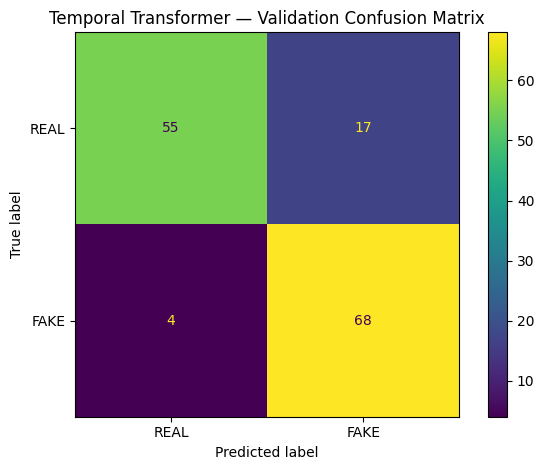

In [31]:

# Step 10.13.7.5 — Detailed validation evaluation

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    f1_score
)

# Load the trusted checkpoint saved by our own training cell
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Saved validation F1:", checkpoint["best_val_f1"])

true_labels = []
predicted_labels = []
fake_probabilities = []

with torch.no_grad():
    for sequences, masks, labels in val_loader:
        sequences = sequences.to(device)
        masks = masks.to(device)

        logits = model(sequences, masks)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.cpu().tolist())
        fake_probabilities.extend(
            probabilities[:, 1].cpu().tolist()
        )

# Metrics
accuracy = accuracy_score(true_labels, predicted_labels)
f1_fake = f1_score(
    true_labels, predicted_labels, pos_label=1,
    zero_division=0
)
auc = roc_auc_score(true_labels, fake_probabilities)

print("BEST CHECKPOINT EVALUATION")
print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Accuracy: {accuracy:.4f}")
print(f"FAKE-class F1: {f1_fake:.4f}")
print(f"ROC-AUC: {auc:.4f}")

print("\nClassification report:")
print(
    classification_report(
        true_labels,
        predicted_labels,
        labels=[0, 1],
        target_names=["REAL", "FAKE"],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    true_labels, predicted_labels, labels=[0, 1]
)

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["REAL", "FAKE"]
)
disp.plot(values_format="d")
plt.title("Temporal Transformer — Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "plots" / "validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(
    true_labels, fake_probabilities
)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Temporal Transformer — Validation ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "plots" / "validation_roc_curve.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Save predictions and metrics for reproducibility
predictions_df = pd.DataFrame({
    "actual_label": true_labels,
    "predicted_label": predicted_labels,
    "fake_probability": fake_probabilities
})

predictions_df.to_csv(
    PROJECT_DIR / "reports" / "validation_predictions.csv",
    index=False
)

print("\nSaved validation plots and predictions.")

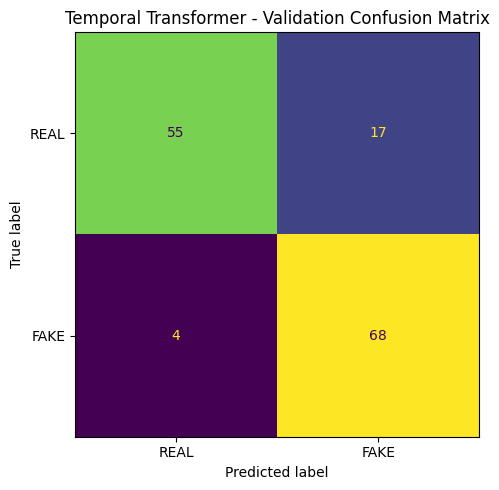

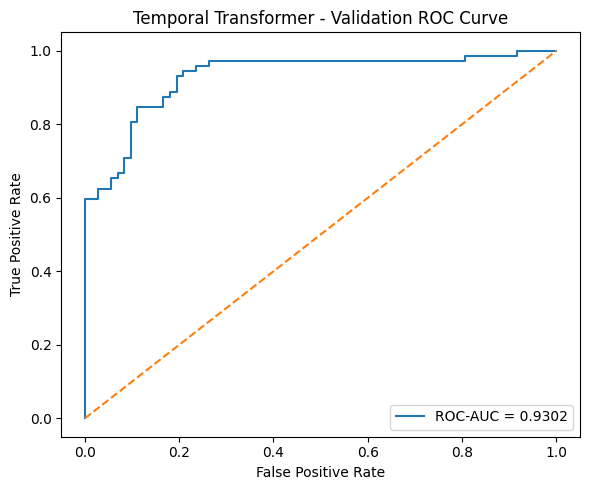

SUCCESS: Evaluation artifacts saved.
Confusion matrix: /kaggle/working/deepfake_authentication_720/plots/validation_confusion_matrix.png
ROC curve: /kaggle/working/deepfake_authentication_720/plots/validation_roc_curve.png
Predictions: /kaggle/working/deepfake_authentication_720/reports/validation_predictions.csv


In [32]:

# Step 10.13.7.6 — Save validation plots and predictions

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score
from pathlib import Path

PLOTS_DIR = PROJECT_DIR / "plots"
REPORT_DIR = PROJECT_DIR / "reports"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Confusion matrix
cm = confusion_matrix(
    true_labels, predicted_labels, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["REAL", "FAKE"]
)
disp.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Temporal Transformer - Validation Confusion Matrix")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 2. ROC curve
fpr, tpr, thresholds = roc_curve(
    true_labels, fake_probabilities
)
auc = roc_auc_score(true_labels, fake_probabilities)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Temporal Transformer - Validation ROC Curve")
ax.legend()
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "validation_roc_curve.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 3. Save per-video predictions
predictions_df = pd.DataFrame({
    "actual_label": true_labels,
    "predicted_label": predicted_labels,
    "fake_probability": fake_probabilities
})

predictions_df.to_csv(
    REPORT_DIR / "validation_predictions.csv",
    index=False
)

print("SUCCESS: Evaluation artifacts saved.")
print("Confusion matrix:", PLOTS_DIR / "validation_confusion_matrix.png")
print("ROC curve:", PLOTS_DIR / "validation_roc_curve.png")
print("Predictions:", REPORT_DIR / "validation_predictions.csv")

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1,val_auc
0,1,0.8499,0.4809,0.6895,0.5556,0.6893,0.8164
1,2,0.6982,0.5104,0.7024,0.5000,0.6667,0.8252
2,3,0.6744,0.5851,0.7135,0.5000,0.6667,0.8252
3,4,0.6487,0.6250,0.8819,0.4931,0.6605,0.8358
4,5,0.7056,0.5920,0.6108,0.5972,0.7041,0.8447
5,6,0.5033,0.7448,0.5116,0.7639,0.7213,0.8601
6,7,0.4226,0.8056,0.5554,0.7639,0.7976,0.8933
7,8,0.3881,0.8212,0.4170,0.7986,0.7717,0.9103
8,9,0.3558,0.8385,0.5817,0.7431,0.6542,0.9230
9,10,0.4540,0.7917,0.3816,0.8542,0.8662,0.9302


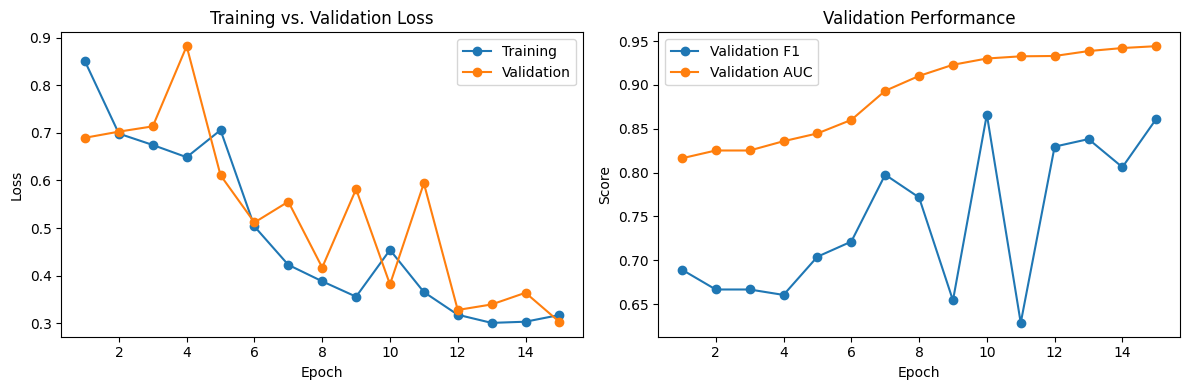

Training history plot saved.


In [33]:

history_df = pd.read_csv(HISTORY_PATH)

display(
    history_df[
        [
            "epoch",
            "train_loss",
            "train_accuracy",
            "val_loss",
            "val_accuracy",
            "val_f1",
            "val_auc"
        ]
    ].round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    marker="o", label="Training"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"],
    marker="o", label="Validation"
)
axes[0].set_title("Training vs. Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"], history_df["val_f1"],
    marker="o", label="Validation F1"
)
axes[1].plot(
    history_df["epoch"], history_df["val_auc"],
    marker="o", label="Validation AUC"
)
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "training_history.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Training history plot saved.")

In [35]:
# Step 10.13.7.9 — Threshold trade-off analysis

import pandas as pd
from sklearn.metrics import confusion_matrix

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    predictions = [
        1 if probability >= threshold else 0
        for probability in fake_probabilities
    ]

    # Rows: actual REAL, FAKE
    # Columns: predicted REAL, FAKE
    tn, fp, fn, tp = confusion_matrix(
        true_labels, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "accuracy": (tn + tp) / (tn + fp + fn + tp),
        "real_false_positive_rate": fp / (tn + fp),
        "fake_recall": tp / (tp + fn),
        "fake_precision": tp / (tp + fp) if tp + fp else 0,
        "false_positives": fp,
        "false_negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,threshold,accuracy,real_false_positive_rate,fake_recall,fake_precision,false_positives,false_negatives
0,0.30,0.7847,0.4028,0.9722,0.7071,29,2
1,0.35,0.8056,0.3611,0.9722,0.7292,26,2
2,0.40,0.8194,0.3333,0.9722,0.7447,24,2
3,0.45,0.8403,0.2917,0.9722,0.7692,21,2
4,0.50,0.8542,0.2361,0.9444,0.8000,17,4
5,0.55,0.8611,0.1944,0.9167,0.8250,14,6
6,0.60,0.8542,0.1944,0.9028,0.8228,14,7
7,0.65,0.8472,0.1667,0.8611,0.8378,12,10
8,0.70,0.8681,0.1111,0.8472,0.8841,8,11


In [37]:
# Step 11.1 — Verify image-classifier source artifacts

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FACES_DIR = PROJECT_DIR / "faces_720"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"
MANIFEST_PATH = PROJECT_DIR / "manifests" / "video_manifest_720.csv"
SPLIT_PATH = PROJECT_DIR / "manifests" / "video_split_720.csv"

for path in [
    FACES_DIR,
    EMBEDDINGS_DIR,
    MANIFEST_PATH,
    SPLIT_PATH
]:
    print(f"{'EXISTS' if path.exists() else 'MISSING'}: {path}")

assert FACES_DIR.exists()
assert EMBEDDINGS_DIR.exists()
assert MANIFEST_PATH.exists()
assert SPLIT_PATH.exists()

manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

print("\nManifest rows:", len(manifest_df))
print("Split rows:", len(split_df))
print("\nVideo split distribution:")
print(pd.crosstab(split_df["split"], split_df["label_name"]))

# Inspect one embedding without processing the entire dataset
sample_embeddings = list(EMBEDDINGS_DIR.rglob("*.npy"))
print("\nEmbedding files found:", len(sample_embeddings))

if sample_embeddings:
    sample_path = sample_embeddings[0]
    sample_embedding = np.load(sample_path, allow_pickle=False)
    print("Sample embedding path:", sample_path)
    print("Sample embedding shape:", sample_embedding.shape)
    print("Sample embedding dtype:", sample_embedding.dtype)
    print("All values finite:", np.isfinite(sample_embedding).all())

EXISTS: /kaggle/working/deepfake_authentication_720/faces_720
EXISTS: /kaggle/working/deepfake_authentication_720/embeddings_720
EXISTS: /kaggle/working/deepfake_authentication_720/manifests/video_manifest_720.csv
EXISTS: /kaggle/working/deepfake_authentication_720/manifests/video_split_720.csv

Manifest rows: 720
Split rows: 720

Video split distribution:
label_name  FAKE  REAL
split                 
train        288   288
val           72    72

Embedding files found: 15250
Sample embedding path: /kaggle/working/deepfake_authentication_720/embeddings_720/REAL/video_0264/frame_08/face_00.npy
Sample embedding shape: (768,)
Sample embedding dtype: float32
All values finite: True


In [38]:

# Step 11.2 — Build frame-level image dataset

from pathlib import Path
import numpy as np
import pandas as pd
from collections import defaultdict

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"
OUTPUT_DIR = PROJECT_DIR / "image_model_data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest_df = pd.read_csv(
    PROJECT_DIR / "manifests" / "video_manifest_720.csv"
)
split_df = pd.read_csv(
    PROJECT_DIR / "manifests" / "video_split_720.csv"
)

# Build video metadata lookup.
video_info = {}

for _, row in split_df.iterrows():
    video_id = int(row["video_id"])
    video_info[video_id] = {
        "label": int(row["label"]),
        "label_name": str(row["label_name"]),
        "split": str(row["split"])
    }

# Collect all face embeddings for each frame.
frame_embeddings = defaultdict(list)

for embedding_path in EMBEDDINGS_DIR.rglob("*.npy"):
    # Expected: LABEL/video_####/frame_##/face_##.npy
    parts = embedding_path.parts

    try:
        label_name = embedding_path.parents[2].name
        video_folder = embedding_path.parents[1].name
        frame_folder = embedding_path.parent.name

        video_id = int(video_folder.replace("video_", ""))
        frame_id = int(frame_folder.replace("frame_", ""))

        if video_id not in video_info:
            continue

        info = video_info[video_id]

        # Guard against a folder/manifest label mismatch.
        if label_name != info["label_name"]:
            raise ValueError(
                f"Label mismatch for video {video_id}: "
                f"{label_name} vs {info['label_name']}"
            )

        embedding = np.load(
            embedding_path, allow_pickle=False
        ).astype(np.float32)

        if embedding.shape != (768,):
            continue
        if not np.isfinite(embedding).all():
            continue

        key = (video_id, frame_id)
        frame_embeddings[key].append(embedding)

    except ValueError:
        raise
    except Exception as exc:
        print("Skipped:", embedding_path, "|", exc)

# Mean-pool all faces in each frame.
records = []

for (video_id, frame_id), embeddings in sorted(frame_embeddings.items()):
    info = video_info[video_id]

    frame_vector = np.mean(
        np.stack(embeddings, axis=0), axis=0
    )

    norm = np.linalg.norm(frame_vector)
    if norm > 0:
        frame_vector = frame_vector / norm

    records.append({
        "video_id": video_id,
        "frame_id": frame_id,
        "label": info["label"],
        "label_name": info["label_name"],
        "split": info["split"],
        "embedding": frame_vector.astype(np.float32)
    })

print("Frames with valid face embeddings:", len(records))
print("Unique videos represented:", len({
    record["video_id"] for record in records
}))

# Save embeddings and metadata separately.
if not records:
    raise RuntimeError("No valid image-level embeddings were created.")

X = np.stack([record["embedding"] for record in records])
metadata_df = pd.DataFrame([
    {key: value for key, value in record.items()
     if key != "embedding"}
    for record in records
])

np.save(OUTPUT_DIR / "X.npy", X)
metadata_df.to_csv(
    OUTPUT_DIR / "metadata.csv", index=False
)

print("Embedding matrix shape:", X.shape)
print("\nSplit/class counts:")
print(pd.crosstab(metadata_df["split"], metadata_df["label_name"]))

# Verify no video leakage.
train_ids = set(
    metadata_df.loc[metadata_df["split"] == "train", "video_id"]
)
val_ids = set(
    metadata_df.loc[metadata_df["split"] == "val", "video_id"]
)

assert train_ids.isdisjoint(val_ids)
assert X.shape[1] == 768
assert np.isfinite(X).all()

print("\nSUCCESS: Image-level dataset created.")
print("Saved to:", OUTPUT_DIR)

Frames with valid face embeddings: 11350
Unique videos represented: 720
Embedding matrix shape: (11350, 768)

Split/class counts:
label_name  FAKE  REAL
split                 
train       4576  4502
val         1143  1129

SUCCESS: Image-level dataset created.
Saved to: /kaggle/working/deepfake_authentication_720/image_model_data


In [39]:

# Step 11.3 — Create MLP datasets and model

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
IMAGE_DATA_DIR = PROJECT_DIR / "image_model_data"

X = np.load(
    IMAGE_DATA_DIR / "X.npy",
    allow_pickle=False
)
metadata_df = pd.read_csv(IMAGE_DATA_DIR / "metadata.csv")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ImageEmbeddingDataset(Dataset):
    def __init__(self, X, metadata):
        self.X = torch.from_numpy(
            X.astype(np.float32, copy=False)
        )
        self.labels = torch.tensor(
            metadata["label"].to_numpy(dtype=np.int64),
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.X[index], self.labels[index]


train_mask = metadata_df["split"].eq("train").to_numpy()
val_mask = metadata_df["split"].eq("val").to_numpy()

train_dataset = ImageEmbeddingDataset(
    X[train_mask],
    metadata_df.loc[train_mask].reset_index(drop=True)
)
val_dataset = ImageEmbeddingDataset(
    X[val_mask],
    metadata_df.loc[val_mask].reset_index(drop=True)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


class ImageMLP(nn.Module):
    def __init__(self, input_dim=768, dropout=0.3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)


mlp_model = ImageMLP().to(device)

print("Device:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in mlp_model.parameters() if p.requires_grad):,}"
)

# Verify a batch and forward pass.
batch_x, batch_y = next(iter(train_loader))
with torch.no_grad():
    batch_logits = mlp_model(batch_x.to(device))

print("\nInput shape:", tuple(batch_x.shape))
print("Labels shape:", tuple(batch_y.shape))
print("Logits shape:", tuple(batch_logits.shape))
print("Finite logits:", torch.isfinite(batch_logits).all().item())

assert batch_x.shape[1] == 768
assert batch_logits.shape == (len(batch_y), 2)
assert torch.isfinite(batch_logits).all()

print("\nSUCCESS: MLP model and DataLoaders are ready.")

Device: cuda
Training samples: 9078
Validation samples: 2272
Training batches: 71
Validation batches: 18
Trainable parameters: 213,442

Input shape: (128, 768)
Labels shape: (128,)
Logits shape: (128, 2)
Finite logits: True

SUCCESS: MLP model and DataLoaders are ready.


In [40]:

# STEP 11.4 — Train the Image MLP

from pathlib import Path
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# --------------------------------------------------
# 1. Configuration and output directories
# --------------------------------------------------
PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
REPORT_DIR = PROJECT_DIR / "reports"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "image_mlp_best.pt"
HISTORY_PATH = REPORT_DIR / "image_mlp_training_history.csv"

EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 6

# Class mapping: 0 = REAL, 1 = FAKE
FAKE_CLASS = 1

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    mlp_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Starting Image MLP training")
print("Device:", device)
print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)


# --------------------------------------------------
# 2. Evaluation helper
# --------------------------------------------------
def evaluate_image_mlp(model, loader):
    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            probabilities = torch.softmax(logits, dim=1)

            total_loss += loss.item() * batch_y.size(0)
            total_samples += batch_y.size(0)

            all_labels.extend(batch_y.cpu().numpy().tolist())
            all_probs.extend(probabilities[:, FAKE_CLASS].cpu().numpy().tolist())

    y_true = np.asarray(all_labels, dtype=np.int64)
    fake_probs = np.asarray(all_probs, dtype=np.float64)
    y_pred = (fake_probs >= 0.5).astype(np.int64)

    metrics = {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, pos_label=FAKE_CLASS, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, pos_label=FAKE_CLASS, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, pos_label=FAKE_CLASS, zero_division=0
        ),
        "auc": (
            roc_auc_score(y_true, fake_probs)
            if len(np.unique(y_true)) == 2 else float("nan")
        ),
    }

    return metrics


# --------------------------------------------------
# 3. Training loop with early stopping
# --------------------------------------------------
history = []
best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
best_state = None

for epoch in range(1, EPOCHS + 1):
    mlp_model.train()

    running_loss = 0.0
    total_samples = 0
    train_labels = []
    train_predictions = []

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = mlp_model(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_y.size(0)
        total_samples += batch_y.size(0)

        predictions = logits.argmax(dim=1)
        train_labels.extend(batch_y.detach().cpu().numpy().tolist())
        train_predictions.extend(predictions.detach().cpu().numpy().tolist())

    train_loss = running_loss / total_samples
    train_accuracy = accuracy_score(train_labels, train_predictions)
    train_f1 = f1_score(
        train_labels, train_predictions,
        pos_label=FAKE_CLASS, zero_division=0
    )

    val_metrics = evaluate_image_mlp(mlp_model, val_loader)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_f1": train_f1,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_auc": val_metrics["auc"],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(row)

    improved = val_metrics["f1"] > best_val_f1

    if improved:
        best_val_f1 = val_metrics["f1"]
        best_epoch = epoch
        epochs_without_improvement = 0
        best_state = copy.deepcopy(mlp_model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_f1": float(best_val_f1),
                "input_dim": 768,
                "class_mapping": {"REAL": 0, "FAKE": 1},
                "threshold": 0.5,
            },
            BEST_MODEL_PATH
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_accuracy:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.4f} | "
        f"Val FAKE F1: {val_metrics['f1']:.4f} | "
        f"Val AUC: {val_metrics['auc']:.4f}"
        f"{'  <-- best checkpoint' if improved else ''}"
    )

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break


# --------------------------------------------------
# 4. Restore the best model and report its metrics
# --------------------------------------------------
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)
mlp_model.load_state_dict(checkpoint["model_state_dict"])

best_metrics = evaluate_image_mlp(mlp_model, val_loader)

print("\n" + "=" * 60)
print("IMAGE MLP TRAINING COMPLETE")
print("=" * 60)
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation FAKE F1: {checkpoint['best_val_f1']:.4f}")
print(f"Validation accuracy:     {best_metrics['accuracy']:.4f}")
print(f"FAKE precision:           {best_metrics['precision']:.4f}")
print(f"FAKE recall:              {best_metrics['recall']:.4f}")
print(f"FAKE F1:                  {best_metrics['f1']:.4f}")
print(f"ROC-AUC:                  {best_metrics['auc']:.4f}")
print("\nCheckpoint:", BEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)
print("SUCCESS: Best image MLP checkpoint restored.")

Starting Image MLP training
Device: cuda
Maximum epochs: 30
Early stopping patience: 6
Epoch 01/30 | Train loss: 0.5291 | Train acc: 0.7470 | Val loss: 0.3800 | Val acc: 0.8160 | Val FAKE F1: 0.8097 | Val AUC: 0.9092  <-- best checkpoint
Epoch 02/30 | Train loss: 0.3166 | Train acc: 0.8583 | Val loss: 0.3177 | Val acc: 0.8587 | Val FAKE F1: 0.8494 | Val AUC: 0.9406  <-- best checkpoint
Epoch 03/30 | Train loss: 0.2568 | Train acc: 0.8915 | Val loss: 0.2764 | Val acc: 0.8820 | Val FAKE F1: 0.8813 | Val AUC: 0.9521  <-- best checkpoint
Epoch 04/30 | Train loss: 0.2246 | Train acc: 0.9096 | Val loss: 0.2852 | Val acc: 0.8798 | Val FAKE F1: 0.8736 | Val AUC: 0.9541
Epoch 05/30 | Train loss: 0.2047 | Train acc: 0.9146 | Val loss: 0.2626 | Val acc: 0.8944 | Val FAKE F1: 0.8928 | Val AUC: 0.9575  <-- best checkpoint
Epoch 06/30 | Train loss: 0.1837 | Train acc: 0.9277 | Val loss: 0.2661 | Val acc: 0.8860 | Val FAKE F1: 0.8886 | Val AUC: 0.9585
Epoch 07/30 | Train loss: 0.1661 | Train acc: 0.9

In [41]:

# STEP 11.5.1 — Frame-Level Evaluation: Predictions and Metrics

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
IMAGE_DATA_DIR = PROJECT_DIR / "image_model_data"
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "image_mlp_best.pt"
REPORT_DIR = PROJECT_DIR / "reports"
PLOT_DIR = PROJECT_DIR / "plots"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load embeddings and metadata
X = np.load(IMAGE_DATA_DIR / "X.npy", allow_pickle=False)
metadata_df = pd.read_csv(IMAGE_DATA_DIR / "metadata.csv")

assert len(X) == len(metadata_df), "Embedding/metadata count mismatch."
assert set(metadata_df["split"].unique()).issubset({"train", "val"})

val_mask = metadata_df["split"].eq("val").to_numpy()
X_val = X[val_mask].astype(np.float32, copy=False)
val_metadata = metadata_df.loc[val_mask].copy().reset_index(drop=True)

y_true = val_metadata["label"].to_numpy(dtype=np.int64)

# 2. Recreate the trained MLP architecture
class ImageMLP(nn.Module):
    def __init__(self, input_dim=768, dropout=0.3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        return self.network(x)

mlp_model = ImageMLP().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True,
)
mlp_model.load_state_dict(checkpoint["model_state_dict"])
mlp_model.eval()

# 3. Predict validation frames in batches
probability_batches = []

with torch.no_grad():
    for start in range(0, len(X_val), 256):
        batch = torch.from_numpy(X_val[start:start + 256]).to(device)
        logits = mlp_model(batch)
        fake_probs = torch.softmax(logits, dim=1)[:, 1]
        probability_batches.append(fake_probs.cpu().numpy())

fake_probabilities = np.concatenate(probability_batches)
assert len(fake_probabilities) == len(y_true)
assert np.isfinite(fake_probabilities).all()

# 4. Calculate metrics at threshold 0.50
threshold = 0.50
y_pred = (fake_probabilities >= threshold).astype(np.int64)

metrics = {
    "validation_frames": len(y_true),
    "threshold": threshold,
    "accuracy": accuracy_score(y_true, y_pred),
    "fake_precision": precision_score(
        y_true, y_pred, pos_label=1, zero_division=0
    ),
    "fake_recall": recall_score(
        y_true, y_pred, pos_label=1, zero_division=0
    ),
    "fake_f1": f1_score(
        y_true, y_pred, pos_label=1, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_true, fake_probabilities),
}

print("=" * 55)
print("IMAGE MLP — FRAME-LEVEL VALIDATION")
print("=" * 55)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Device:", device)
print("Validation frames:", len(y_true))
print(f"Accuracy:       {metrics['accuracy']:.4f}")
print(f"FAKE precision: {metrics['fake_precision']:.4f}")
print(f"FAKE recall:    {metrics['fake_recall']:.4f}")
print(f"FAKE F1:        {metrics['fake_f1']:.4f}")
print(f"ROC-AUC:        {metrics['roc_auc']:.4f}")

print("\nConfusion matrix (rows=actual, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["REAL", "FAKE"],
    zero_division=0,
))

# 5. Save per-frame predictions
prediction_df = val_metadata.copy()
prediction_df["fake_probability"] = fake_probabilities
prediction_df["predicted_label"] = y_pred
prediction_df["predicted_label_name"] = np.where(
    y_pred == 1, "FAKE", "REAL"
)

prediction_path = REPORT_DIR / "image_mlp_frame_level_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

metrics_path = REPORT_DIR / "image_mlp_frame_level_metrics.csv"
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

print("\nSaved predictions:", prediction_path)
print("Saved metrics:", metrics_path)
print("\nSUCCESS: Frame-level evaluation completed.")

IMAGE MLP — FRAME-LEVEL VALIDATION
Checkpoint epoch: 15
Device: cuda
Validation frames: 2272
Accuracy:       0.9120
FAKE precision: 0.9244
FAKE recall:    0.8985
FAKE F1:        0.9113
ROC-AUC:        0.9693

Confusion matrix (rows=actual, columns=predicted):
[[1045   84]
 [ 116 1027]]

Classification report:
              precision    recall  f1-score   support

        REAL       0.90      0.93      0.91      1129
        FAKE       0.92      0.90      0.91      1143

    accuracy                           0.91      2272
   macro avg       0.91      0.91      0.91      2272
weighted avg       0.91      0.91      0.91      2272


Saved predictions: /kaggle/working/deepfake_authentication_720/reports/image_mlp_frame_level_predictions.csv
Saved metrics: /kaggle/working/deepfake_authentication_720/reports/image_mlp_frame_level_metrics.csv

SUCCESS: Frame-level evaluation completed.


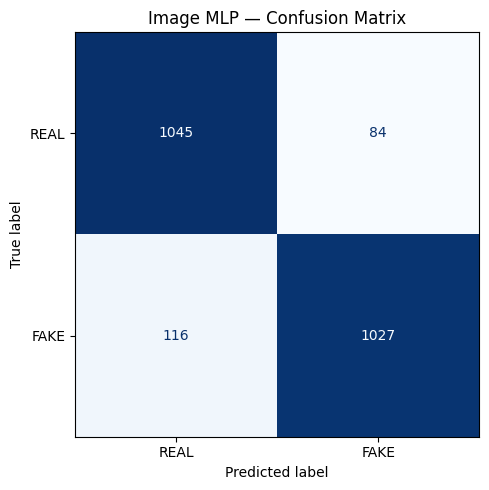

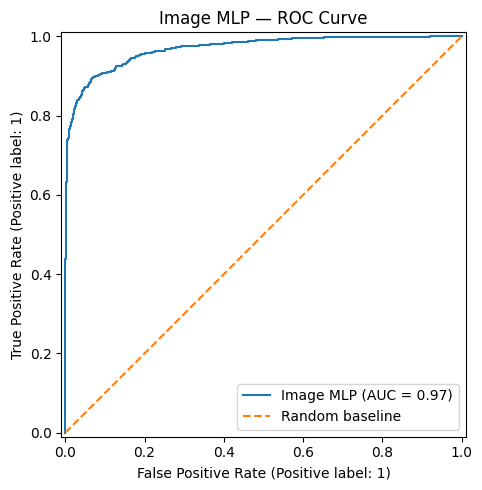

Saved confusion matrix: /kaggle/working/deepfake_authentication_720/plots/image_mlp_confusion_matrix.png
Saved ROC curve: /kaggle/working/deepfake_authentication_720/plots/image_mlp_roc_curve.png


In [42]:

# STEP 11.5.2 — Plot and Save Evaluation Curves

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1],
    display_labels=["REAL", "FAKE"],
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title("Image MLP — Confusion Matrix")
fig.tight_layout()

cm_path = PLOT_DIR / "image_mlp_confusion_matrix.png"
fig.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ROC curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_true,
    fake_probabilities,
    name="Image MLP",
    ax=ax,
)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("Image MLP — ROC Curve")
ax.legend()
fig.tight_layout()

roc_path = PLOT_DIR / "image_mlp_roc_curve.png"
fig.savefig(roc_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved confusion matrix:", cm_path)
print("Saved ROC curve:", roc_path)

In [43]:

# STEP 11.5.3 — Threshold Analysis

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

threshold_rows = []

for threshold in np.arange(0.30, 0.76, 0.05):
    predictions = (fake_probabilities >= threshold).astype(np.int64)

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_true, predictions),
        "fake_precision": precision_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "fake_recall": recall_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "fake_f1": f1_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

threshold_path = REPORT_DIR / "image_mlp_threshold_analysis.csv"
threshold_df.to_csv(threshold_path, index=False)
print("Saved threshold analysis:", threshold_path)

,threshold,accuracy,fake_precision,fake_recall,fake_f1
0,0.30,0.9001,0.8928,0.9108,0.9017
1,0.35,0.9045,0.9026,0.9081,0.9054
2,0.40,0.9067,0.9073,0.9073,0.9073
3,0.45,0.9089,0.9149,0.9029,0.9089
4,0.50,0.9120,0.9244,0.8985,0.9113
5,0.55,0.9120,0.9330,0.8889,0.9104
6,0.60,0.9089,0.9374,0.8775,0.9065
7,0.65,0.9102,0.9476,0.8696,0.9069
8,0.70,0.9089,0.9500,0.8644,0.9052
9,0.75,0.9040,0.9557,0.8486,0.8990


Saved threshold analysis: /kaggle/working/deepfake_authentication_720/reports/image_mlp_threshold_analysis.csv


In [44]:

# STEP 12.1 — Verify image inference dependencies and artifacts

from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import torch

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")

required_paths = {
    "Image MLP checkpoint":
        PROJECT_DIR / "checkpoints" / "image_mlp_best.pt",
    "Image embeddings":
        PROJECT_DIR / "image_model_data" / "X.npy",
    "Image metadata":
        PROJECT_DIR / "image_model_data" / "metadata.csv",
    "Video manifest":
        PROJECT_DIR / "manifests" / "video_manifest_720.csv",
}

print("=" * 65)
print("IMAGE INFERENCE ENVIRONMENT CHECK")
print("=" * 65)

for name, path in required_paths.items():
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {name}")
    print(f"  Path: {path}")

print("\n--- Runtime ---")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n--- Required libraries ---")
for package in [
    "facenet_pytorch",
    "open_clip",
    "transformers",
    "PIL",
    "cv2",
]:
    module_name = {
        "facenet_pytorch": "facenet_pytorch",
        "open_clip": "open_clip",
        "transformers": "transformers",
        "PIL": "PIL",
        "cv2": "cv2",
    }[package]

    print(
        f"{package}:",
        "AVAILABLE" if importlib.util.find_spec(module_name) else "NOT FOUND"
    )

print("\n--- Embedding dataset ---")
x_path = required_paths["Image embeddings"]
metadata_path = required_paths["Image metadata"]

if x_path.exists() and metadata_path.exists():
    X = np.load(x_path, mmap_mode="r", allow_pickle=False)
    metadata = pd.read_csv(metadata_path)

    print("Embedding shape:", X.shape)
    print("Embedding dtype:", X.dtype)
    print("Metadata rows:", len(metadata))
    print("Metadata columns:", metadata.columns.tolist())

    if X.ndim == 2 and X.shape[1] == 768:
        print("Embedding dimension: matches expected ViT-L/14 output")
    else:
        print("WARNING: unexpected embedding shape")

print("\n--- Cached model directories ---")
cache_roots = [
    Path("/kaggle/working"),
    Path("/root/.cache"),
    Path("/root/.cache/huggingface"),
    Path("/root/.cache/torch"),
]

for root in cache_roots:
    if root.exists():
        print(f"\n{root}")
        try:
            for child in list(root.iterdir())[:20]:
                print(" ", child.name)
        except PermissionError:
            print("  Cannot inspect directory")

print("\n--- Face and embedding artifact directories ---")
for name in ["faces_720", "embeddings_720", "frames_720"]:
    path = PROJECT_DIR / name
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    if path.exists():
        print("  Example entries:", [p.name for p in list(path.iterdir())[:5]])

print("\nEnvironment audit complete.")

IMAGE INFERENCE ENVIRONMENT CHECK
FOUND: Image MLP checkpoint
  Path: /kaggle/working/deepfake_authentication_720/checkpoints/image_mlp_best.pt
FOUND: Image embeddings
  Path: /kaggle/working/deepfake_authentication_720/image_model_data/X.npy
FOUND: Image metadata
  Path: /kaggle/working/deepfake_authentication_720/image_model_data/metadata.csv
FOUND: Video manifest
  Path: /kaggle/working/deepfake_authentication_720/manifests/video_manifest_720.csv

--- Runtime ---
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

--- Required libraries ---
facenet_pytorch: AVAILABLE
open_clip: AVAILABLE
transformers: AVAILABLE
PIL: AVAILABLE
cv2: AVAILABLE

--- Embedding dataset ---
Embedding shape: (11350, 768)
Embedding dtype: float32
Metadata rows: 11350
Metadata columns: ['video_id', 'frame_id', 'label', 'label_name', 'split']
Embedding dimension: matches expected ViT-L/14 output

--- Cached model directories ---

/kaggle/working
  .virtual_documents
  deepfake_authentication_720

/root/.

In [45]:

# STEP 12.2 — Inspect Face Crops and ViT Embedding Artifacts

from pathlib import Path
import numpy as np

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")

for folder_name in ["faces_720", "embeddings_720"]:
    root = PROJECT_DIR / folder_name

    print("\n" + "=" * 65)
    print(f"INSPECTING: {folder_name}")
    print("=" * 65)

    if not root.exists():
        print("Directory missing:", root)
        continue

    # Show a few representative paths
    files = [
        p for p in root.rglob("*")
        if p.is_file()
    ]

    print("Total files:", len(files))
    print("Example files:")
    for path in files[:8]:
        print(" ", path.relative_to(root))

    # Inspect the first NumPy embedding, if present
    npy_files = [p for p in files if p.suffix.lower() == ".npy"]

    if npy_files:
        sample_path = npy_files[0]
        try:
            arr = np.load(sample_path, allow_pickle=False)
            print("\nSample NumPy file:", sample_path)
            print("Shape:", arr.shape)
            print("Dtype:", arr.dtype)
            print("All finite:", np.isfinite(arr).all())

            if arr.ndim == 1:
                print("L2 norm:", float(np.linalg.norm(arr)))
        except Exception as exc:
            print("Could not inspect sample NumPy file:", repr(exc))

# Inspect the most likely local model caches
print("\n" + "=" * 65)
print("MODEL CACHE INSPECTION")
print("=" * 65)

cache_roots = [
    Path("/root/.cache/huggingface/hub"),
    Path("/root/.cache/torch"),
    Path("/kaggle/input"),
]

for root in cache_roots:
    print(f"\n{root}: {'FOUND' if root.exists() else 'MISSING'}")

    if not root.exists():
        continue

    shown = 0
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in {
            ".pt", ".pth", ".bin", ".safetensors", ".onnx"
        }:
            print(" ", path)
            shown += 1
            if shown >= 15:
                print(" ... additional files omitted")
                break

print("\nInspection complete. No files were changed.")


INSPECTING: faces_720
Total files: 38290
Example files:
  REAL/video_0264/frame_08/_complete.json
  REAL/video_0264/frame_08/face_00.jpg
  REAL/video_0264/frame_08/detections.json
  REAL/video_0264/frame_14/_complete.json
  REAL/video_0264/frame_14/face_00.jpg
  REAL/video_0264/frame_14/detections.json
  REAL/video_0264/frame_15/_complete.json
  REAL/video_0264/frame_15/face_00.jpg

INSPECTING: embeddings_720
Total files: 15250
Example files:
  REAL/video_0264/frame_08/face_00.npy
  REAL/video_0264/frame_14/face_00.npy
  REAL/video_0264/frame_15/face_00.npy
  REAL/video_0264/frame_02/face_00.npy
  REAL/video_0264/frame_09/face_00.npy
  REAL/video_0264/frame_10/face_00.npy
  REAL/video_0264/frame_12/face_00.npy
  REAL/video_0264/frame_05/face_00.npy

Sample NumPy file: /kaggle/working/deepfake_authentication_720/embeddings_720/REAL/video_0264/frame_08/face_00.npy
Shape: (768,)
Dtype: float32
All finite: True
L2 norm: 1.0

MODEL CACHE INSPECTION

/root/.cache/huggingface/hub: FOUND
  /r

In [46]:

# STEP 12.3 — Verify ViT-L/14 Model and Embedding Compatibility

from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import open_clip
from PIL import Image

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FACES_DIR = PROJECT_DIR / "faces_720"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings_720"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("OpenCLIP version:", getattr(open_clip, "__version__", "unknown"))

# 1. Load the expected pretrained ViT-L/14 model.
# This should use the checkpoint already cached in the environment.
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-L-14",
    pretrained="openai",
    device=device,
)
model.eval()

print("Model loaded: ViT-L/14, pretrained=openai")

# 2. Find an existing face crop and its saved embedding.
face_paths = sorted(FACES_DIR.rglob("face_00.jpg"))
if not face_paths:
    raise FileNotFoundError(f"No face_00.jpg files found under {FACES_DIR}")

face_path = face_paths[0]
relative_path = face_path.relative_to(FACES_DIR)
embedding_path = EMBEDDINGS_DIR / relative_path.with_suffix(".npy")

if not embedding_path.exists():
    raise FileNotFoundError(
        f"Matching embedding not found: {embedding_path}"
    )

print("Sample face:", face_path)
print("Saved embedding:", embedding_path)

# 3. Recreate the embedding using the cached model.
with Image.open(face_path) as image:
    image = image.convert("RGB")
    input_tensor = preprocess(image).unsqueeze(0).to(device)

with torch.no_grad():
    image_features = model.encode_image(input_tensor)
    image_features = F.normalize(image_features.float(), p=2, dim=1)

new_embedding = image_features[0].cpu().numpy().astype(np.float32)
saved_embedding = np.load(embedding_path, allow_pickle=False)

print("\nSaved embedding shape:", saved_embedding.shape)
print("New embedding shape:", new_embedding.shape)
print("New embedding finite:", np.isfinite(new_embedding).all())
print("New embedding L2 norm:", np.linalg.norm(new_embedding))

if new_embedding.shape != (768,) or saved_embedding.shape != (768,):
    raise ValueError("Embedding dimensions do not match expected (768,).")

# 4. Compare vectors to check preprocessing/model compatibility.
cosine_similarity = float(
    np.dot(new_embedding, saved_embedding)
    / (
        np.linalg.norm(new_embedding)
        * np.linalg.norm(saved_embedding)
        + 1e-12
    )
)

max_abs_difference = float(
    np.max(np.abs(new_embedding - saved_embedding))
)

print("\nCosine similarity with saved embedding:", cosine_similarity)
print("Maximum absolute difference:", max_abs_difference)

if cosine_similarity > 0.999:
    print("\nSUCCESS: Recreated embedding closely matches the saved embedding.")
else:
    print(
        "\nWARNING: Embeddings differ. We must investigate preprocessing "
        "or model differences before trusting image predictions."
    )

Device: cuda
OpenCLIP version: 3.3.0


/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Model loaded: ViT-L/14, pretrained=openai
Sample face: /kaggle/working/deepfake_authentication_720/faces_720/FAKE/video_0004/frame_00/face_00.jpg
Saved embedding: /kaggle/working/deepfake_authentication_720/embeddings_720/FAKE/video_0004/frame_00/face_00.npy

Saved embedding shape: (768,)
New embedding shape: (768,)
New embedding finite: True
New embedding L2 norm: 1.0

Cosine similarity with saved embedding: 1.0
Maximum absolute difference: 3.0547380447387695e-07

SUCCESS: Recreated embedding closely matches the saved embedding.


In [47]:

# STEP 12.4 — Complete Image Inference Pipeline

from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import open_clip

from PIL import Image
from torchvision.transforms import ToPILImage
from facenet_pytorch import MTCNN

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------
PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "image_mlp_best.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_THRESHOLD = 0.50

assert CHECKPOINT_PATH.exists(), (
    f"Missing MLP checkpoint: {CHECKPOINT_PATH}"
)

# --------------------------------------------------
# 2. Load the face detector
# --------------------------------------------------
# Detect every face rather than selecting only the largest one.
mtcnn = MTCNN(
    image_size=160,
    margin=0,
    keep_all=True,
    post_process=False,
    device=device,
)

to_pil = ToPILImage()

# --------------------------------------------------
# 3. Load the verified ViT-L/14 feature extractor
# --------------------------------------------------
# Uses the same configuration that reproduced the saved embedding.
vit_model, _, vit_preprocess = open_clip.create_model_and_transforms(
    "ViT-L-14",
    pretrained="openai",
    device=device,
)
vit_model.eval()

# --------------------------------------------------
# 4. Recreate and load the trained MLP
# --------------------------------------------------
class ImageMLP(nn.Module):
    def __init__(self, input_dim=768, dropout=0.3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        return self.network(x)


mlp_model = ImageMLP().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True,
)
mlp_model.load_state_dict(checkpoint["model_state_dict"])
mlp_model.eval()

print("Face detector, ViT-L/14, and trained MLP loaded.")
print("Best MLP checkpoint epoch:", checkpoint["epoch"])
print("Prediction threshold:", IMAGE_THRESHOLD)


# --------------------------------------------------
# 5. Image prediction function
# --------------------------------------------------
def predict_image(image_path, threshold=IMAGE_THRESHOLD):
    """
    Predict REAL or FAKE for an image using all detected faces.

    Returns NO_FACE_DETECTED if MTCNN finds no faces.
    The probability is the model's FAKE-class probability,
    not a guarantee of real-world authenticity.
    """
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    if not 0.0 < threshold < 1.0:
        raise ValueError("threshold must be between 0 and 1.")

    # Load and standardize image color mode.
    with Image.open(image_path) as opened:
        image = opened.convert("RGB")

    # MTCNN returns all face crops, or None when no face is detected.
    face_crops = mtcnn(image)

    if face_crops is None:
        return {
            "status": "NO_FACE_DETECTED",
            "prediction": None,
            "fake_probability": None,
            "face_count": 0,
            "message": (
                "No face was detected. The image was not classified "
                "by the face-based MLP."
            ),
        }

    if face_crops.ndim == 3:
        face_crops = face_crops.unsqueeze(0)

    # Convert MTCNN crops to PIL images, then apply the exact
    # OpenCLIP preprocessing used for the verified saved embedding.
    face_tensors = []

    for face_crop in face_crops:
        face_crop = face_crop.detach().cpu().clamp(0, 1)
        face_image = to_pil(face_crop)
        face_tensors.append(vit_preprocess(face_image))

    batch = torch.stack(face_tensors).to(device)

    # Extract normalized embedding for each face.
    with torch.no_grad():
        face_embeddings = vit_model.encode_image(batch).float()
        face_embeddings = F.normalize(
            face_embeddings, p=2, dim=1
        )

        # Match training: mean-pool all face embeddings, then L2-normalize.
        image_embedding = face_embeddings.mean(dim=0, keepdim=True)
        image_embedding = F.normalize(
            image_embedding, p=2, dim=1
        )

        # Run the trained image MLP.
        logits = mlp_model(image_embedding)
        probabilities = torch.softmax(logits, dim=1)[0]

    fake_probability = float(probabilities[1].item())
    real_probability = float(probabilities[0].item())

    prediction = (
        "FAKE" if fake_probability >= threshold else "REAL"
    )

    return {
        "status": "SUCCESS",
        "prediction": prediction,
        "fake_probability": fake_probability,
        "real_probability": real_probability,
        "face_count": int(face_crops.shape[0]),
        "threshold": float(threshold),
        "message": (
            "Prediction generated by the face-based image MLP. "
            "This is a model estimate, not definitive proof of authenticity."
        ),
    }


print("\nSUCCESS: Image inference function is ready.")

Face detector, ViT-L/14, and trained MLP loaded.
Best MLP checkpoint epoch: 15
Prediction threshold: 0.5

SUCCESS: Image inference function is ready.


In [48]:

# STEP 12.5 — Smoke Test on an Existing Frame

from pathlib import Path
import json

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
FRAMES_DIR = PROJECT_DIR / "frames_720"

frame_candidates = sorted(
    p for p in FRAMES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not frame_candidates:
    raise FileNotFoundError(
        f"No frame images found under {FRAMES_DIR}"
    )

test_image = frame_candidates[0]
result = predict_image(test_image)

print("Test image:", test_image)
print("Inference result:")
print(json.dumps(result, indent=2))

assert result["status"] in {"SUCCESS", "NO_FACE_DETECTED"}

if result["status"] == "SUCCESS":
    assert result["prediction"] in {"REAL", "FAKE"}
    assert 0.0 <= result["fake_probability"] <= 1.0
    assert result["face_count"] > 0

print("\nSUCCESS: Image inference smoke test completed.")

Test image: /kaggle/working/deepfake_authentication_720/frames_720/FAKE/video_0004/frame_00.jpg
Inference result:
{
  "status": "SUCCESS",
  "prediction": "REAL",
  "fake_probability": 0.0009318761294707656,
  "real_probability": 0.9990682005882263,
  "face_count": 1,
  "threshold": 0.5,
  "message": "Prediction generated by the face-based image MLP. This is a model estimate, not definitive proof of authenticity."
}

SUCCESS: Image inference smoke test completed.


In [49]:
from PIL import Image
from pathlib import Path

test_dir = PROJECT_DIR / "reports" / "inference_tests"
test_dir.mkdir(parents=True, exist_ok=True)

blank_image_path = test_dir / "blank_no_face_test.png"
Image.new("RGB", (512, 512), color=(240, 240, 240)).save(blank_image_path)

no_face_result = predict_image(blank_image_path)

print("No-face test result:")
print(no_face_result)

assert no_face_result["status"] == "NO_FACE_DETECTED"
assert no_face_result["prediction"] is None

print("\nSUCCESS: No-face handling works.")

No-face test result:
{'status': 'NO_FACE_DETECTED', 'prediction': None, 'fake_probability': None, 'face_count': 0, 'message': 'No face was detected. The image was not classified by the face-based MLP.'}

SUCCESS: No-face handling works.


In [50]:
from pathlib import Path
from PIL import Image

multi_face_image = None
checked_frames = 0
max_frames_to_check = 100

for candidate in frame_candidates[:max_frames_to_check]:
    checked_frames += 1

    with Image.open(candidate) as opened:
        image = opened.convert("RGB")

    detected_faces = mtcnn(image)

    if detected_faces is not None:
        face_count = (
            1 if detected_faces.ndim == 3
            else detected_faces.shape[0]
        )

        if face_count >= 2:
            multi_face_image = candidate
            print("Found multi-face image:", candidate)
            print("Detected faces:", face_count)
            break

if multi_face_image is None:
    print(f"No multi-face frame found in the {checked_frames} frames checked.")
    print("We can expand the search later if needed.")
else:
    multi_face_result = predict_image(multi_face_image)

    print("\nMulti-face inference result:")
    print(multi_face_result)

    assert multi_face_result["status"] == "SUCCESS"
    assert multi_face_result["face_count"] >= 2
    assert multi_face_result["prediction"] in {"REAL", "FAKE"}

    print("\nSUCCESS: Multi-face inference works.")

Found multi-face image: /kaggle/working/deepfake_authentication_720/frames_720/FAKE/video_0004/frame_08.jpg
Detected faces: 2

Multi-face inference result:
{'status': 'SUCCESS', 'prediction': 'REAL', 'fake_probability': 0.0012400149134919047, 'real_probability': 0.9987599849700928, 'face_count': 2, 'threshold': 0.5, 'message': 'Prediction generated by the face-based image MLP. This is a model estimate, not definitive proof of authenticity.'}

SUCCESS: Multi-face inference works.


In [51]:
%pip install -q fastapi uvicorn python-multipart httpx

Note: you may need to restart the kernel to use updated packages.


In [52]:
from pathlib import Path
import importlib.metadata as metadata

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
BACKEND_DIR = PROJECT_DIR / "backend"
BACKEND_DIR.mkdir(parents=True, exist_ok=True)

required_packages = ["fastapi", "uvicorn", "python-multipart", "httpx"]

print("Backend directory:", BACKEND_DIR)
print("\nInstalled package versions:")

for package in required_packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

assert (PROJECT_DIR / "checkpoints" / "image_mlp_best.pt").exists()
assert (PROJECT_DIR / "image_model_data" / "X.npy").exists()

print("\nSUCCESS: Backend directory and model artifacts verified.")

Backend directory: /kaggle/working/deepfake_authentication_720/backend

Installed package versions:
fastapi: 0.141.1
uvicorn: 0.52.4
python-multipart: 0.0.32
httpx: 0.28.1

SUCCESS: Backend directory and model artifacts verified.


In [57]:
import numpy as np
import torch

VIDEO_CHECKPOINT_PATH = (
    "/kaggle/working/deepfake_authentication_720/"
    "checkpoints/temporal_transformer_best.pt"
)

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    np.dtypes.Float64DType,
]

with torch.serialization.safe_globals(safe_types):
    checkpoint = torch.load(
        VIDEO_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )

print("Checkpoint loaded successfully.")
print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nTop-level keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n{key}: dictionary with {len(value)} entries")
            print("Sample keys:", list(value.keys())[:10])
        elif torch.is_tensor(value):
            print(f"{key}: tensor shape {tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__} = {value}")

Checkpoint loaded successfully.
Checkpoint type: dict

Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_f1', 'val_accuracy', 'val_precision', 'val_recall', 'val_auc', 'model_config', 'class_mapping']
epoch: int = 10

model_state_dict: dictionary with 57 entries
Sample keys: ['projection.weight', 'projection.bias', 'positional_encoding.pe', 'transformer.layers.0.self_attn.in_proj_weight', 'transformer.layers.0.self_attn.in_proj_bias', 'transformer.layers.0.self_attn.out_proj.weight', 'transformer.layers.0.self_attn.out_proj.bias', 'transformer.layers.0.linear1.weight', 'transformer.layers.0.linear1.bias', 'transformer.layers.0.linear2.weight']

optimizer_state_dict: dictionary with 2 entries
Sample keys: ['state', 'param_groups']
best_val_f1: float = 0.8662420382165605
val_accuracy: float = 0.8541666666666666
val_precision: float = 0.8
val_recall: float = 0.9444444444444444
val_auc: float64 = 0.9301697530864198

model_config: dictionary with 6 entries
Samp

In [58]:
import numpy as np
import torch
from pathlib import Path

VIDEO_CHECKPOINT_PATH = Path(
    "/kaggle/working/deepfake_authentication_720/"
    "checkpoints/temporal_transformer_best.pt"
)

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    np.dtypes.Float64DType,
]

with torch.serialization.safe_globals(safe_types):
    checkpoint = torch.load(
        VIDEO_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )

print("=" * 60)
print("SAVED MODEL CONFIGURATION")
print("=" * 60)

for key, value in checkpoint["model_config"].items():
    print(f"{key}: {value}")

print("\nClass mapping:")
print(checkpoint["class_mapping"])

print("\n" + "=" * 60)
print("ALL MODEL PARAMETER NAMES AND SHAPES")
print("=" * 60)

for name, tensor in checkpoint["model_state_dict"].items():
    if torch.is_tensor(tensor):
        print(f"{name:55s} {tuple(tensor.shape)}")
    else:
        print(f"{name:55s} {type(tensor).__name__}")

print("\nTotal parameter tensors:", len(checkpoint["model_state_dict"]))
print("Checkpoint epoch:", checkpoint["epoch"])

SAVED MODEL CONFIGURATION
input_dim: 768
d_model: 256
num_heads: 8
num_layers: 4
dropout: 0.1
max_length: 16

Class mapping:
{'REAL': 0, 'FAKE': 1}

ALL MODEL PARAMETER NAMES AND SHAPES
projection.weight                                       (256, 768)
projection.bias                                         (256,)
positional_encoding.pe                                  (1, 16, 256)
transformer.layers.0.self_attn.in_proj_weight           (768, 256)
transformer.layers.0.self_attn.in_proj_bias             (768,)
transformer.layers.0.self_attn.out_proj.weight          (256, 256)
transformer.layers.0.self_attn.out_proj.bias            (256,)
transformer.layers.0.linear1.weight                     (1024, 256)
transformer.layers.0.linear1.bias                       (1024,)
transformer.layers.0.linear2.weight                     (256, 1024)
transformer.layers.0.linear2.bias                       (256,)
transformer.layers.0.norm1.weight                       (256,)
transformer.layers.0.norm1.bi

In [59]:
from pathlib import Path
import math
import numpy as np
import torch
import torch.nn as nn

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
VIDEO_CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / "temporal_transformer_best.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the trusted project checkpoint with the safe allowlist.
safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    np.dtypes.Float64DType,
]

with torch.serialization.safe_globals(safe_types):
    checkpoint = torch.load(
        VIDEO_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )

config = checkpoint["model_config"]


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length, dropout):
        super().__init__()

        position = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(1, max_length, d_model)
        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1), :])


class TemporalTransformer(nn.Module):
    def __init__(
        self,
        input_dim=768,
        d_model=256,
        num_heads=8,
        num_layers=4,
        dropout=0.1,
        max_length=16,
    ):
        super().__init__()

        self.projection = nn.Linear(input_dim, d_model)

        self.positional_encoding = PositionalEncoding(
            d_model=d_model,
            max_length=max_length,
            dropout=dropout,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=1024,
            dropout=dropout,
            batch_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model),
        )

        self.classifier_norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, 2)

    def forward(self, x, attention_mask):
        # x: (batch, sequence_length, 768)
        # attention_mask: (batch, sequence_length), 1=valid, 0=padding
        x = self.projection(x)
        x = self.positional_encoding(x)

        padding_mask = ~attention_mask.bool()

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask,
        )

        valid_mask = attention_mask.unsqueeze(-1).to(x.dtype)
        pooled = (x * valid_mask).sum(dim=1)
        pooled = pooled / valid_mask.sum(dim=1).clamp(min=1.0)

        pooled = self.classifier_norm(pooled)
        return self.classifier(pooled)


video_model = TemporalTransformer(
    input_dim=config["input_dim"],
    d_model=config["d_model"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    dropout=config["dropout"],
    max_length=config["max_length"],
)

# Strict loading verifies the reconstructed parameter names and shapes.
load_result = video_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

video_model = video_model.to(device)
video_model.eval()

print("Strict checkpoint loading:", load_result)
print("Device:", device)
print("Model parameters:", sum(p.numel() for p in video_model.parameters()))
print("Checkpoint epoch:", checkpoint["epoch"])
print("Class mapping:", checkpoint["class_mapping"])
print("\nSUCCESS: All checkpoint parameters loaded.")

Strict checkpoint loading: <All keys matched successfully>
Device: cuda
Model parameters: 3357442
Checkpoint epoch: 10
Class mapping: {'REAL': 0, 'FAKE': 1}

SUCCESS: All checkpoint parameters loaded.


In [60]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
SEQUENCES_DIR = PROJECT_DIR / "sequences_720"
SPLIT_PATH = PROJECT_DIR / "manifests" / "video_split_720.csv"

print("Sequences directory exists:", SEQUENCES_DIR.exists())
print("Split manifest exists:", SPLIT_PATH.exists())

sequence_files = sorted(SEQUENCES_DIR.rglob("*.npz"))
print("Number of sequence files:", len(sequence_files))

if not sequence_files:
    raise FileNotFoundError(f"No .npz sequence files found in {SEQUENCES_DIR}")

with np.load(sequence_files[0], allow_pickle=False) as data:
    print("\nSample sequence:", sequence_files[0])
    print("Stored arrays:", data.files)

    for key in data.files:
        array = data[key]
        print(
            f"{key}: shape={array.shape}, "
            f"dtype={array.dtype}"
        )

if SPLIT_PATH.exists():
    split_df = pd.read_csv(SPLIT_PATH)

    print("\nSplit manifest columns:", split_df.columns.tolist())
    print("Rows:", len(split_df))
    print("\nFirst five rows:")
    display(split_df.head())

Sequences directory exists: True
Split manifest exists: True
Number of sequence files: 720

Sample sequence: /kaggle/working/deepfake_authentication_720/sequences_720/FAKE/sequence_0004.npz
Stored arrays: ['sequence', 'attention_mask', 'label', 'frame_indices', 'video_id', 'label_name', 'split']
sequence: shape=(16, 768), dtype=float32
attention_mask: shape=(16,), dtype=float32
label: shape=(), dtype=int64
frame_indices: shape=(16,), dtype=int64
video_id: shape=(), dtype=int64
label_name: shape=(), dtype=<U4
split: shape=(), dtype=<U3

Split manifest columns: ['video_id', 'video_path', 'label', 'label_name', 'split']
Rows: 720

First five rows:


,video_id,video_path,label,label_name,split
0,0,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,train
1,1,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,val
2,2,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,train
3,3,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,0,REAL,train
4,4,/kaggle/input/datasets/sanikatiwarekar/deep-fa...,1,FAKE,val


In [61]:
from pathlib import Path
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

PROJECT_DIR = Path("/kaggle/working/deepfake_authentication_720")
SEQUENCES_DIR = PROJECT_DIR / "sequences_720"

X_val = []
M_val = []
y_val = []
video_ids_val = []

for sequence_path in sorted(SEQUENCES_DIR.rglob("*.npz")):
    with np.load(sequence_path, allow_pickle=False) as data:
        split = str(data["split"].item())

        if split != "val":
            continue

        sequence = data["sequence"].astype(np.float32)
        mask = data["attention_mask"].astype(np.float32)
        label = int(data["label"].item())
        video_id = int(data["video_id"].item())

        if sequence.shape != (16, 768):
            raise ValueError(
                f"Unexpected sequence shape {sequence.shape}: {sequence_path}"
            )

        if mask.shape != (16,):
            raise ValueError(
                f"Unexpected mask shape {mask.shape}: {sequence_path}"
            )

        if not np.isfinite(sequence).all():
            raise ValueError(f"Non-finite embedding values: {sequence_path}")

        if mask.sum() <= 0:
            raise ValueError(f"No valid frames in sequence: {sequence_path}")

        X_val.append(sequence)
        M_val.append(mask)
        y_val.append(label)
        video_ids_val.append(video_id)

X_val = np.stack(X_val)
M_val = np.stack(M_val)
y_val = np.asarray(y_val, dtype=np.int64)

print("Validation sequence tensor:", X_val.shape)
print("Validation mask tensor:", M_val.shape)
print("Validation labels:", y_val.shape)
print("REAL videos:", int((y_val == 0).sum()))
print("FAKE videos:", int((y_val == 1).sum()))
print("Unique validation video IDs:", len(set(video_ids_val)))

assert len(y_val) == 144, f"Expected 144 validation videos, got {len(y_val)}"
assert len(set(video_ids_val)) == len(video_ids_val), "Duplicate validation video IDs"

X_tensor = torch.from_numpy(X_val).to(device)
M_tensor = torch.from_numpy(M_val).to(device)

video_model.eval()

with torch.inference_mode():
    logits = video_model(X_tensor, M_tensor)
    probabilities = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

predictions = (probabilities >= 0.5).astype(np.int64)

accuracy = accuracy_score(y_val, predictions)
precision = precision_score(y_val, predictions, zero_division=0)
recall = recall_score(y_val, predictions, zero_division=0)
f1 = f1_score(y_val, predictions, zero_division=0)
auc = roc_auc_score(y_val, probabilities)
cm = confusion_matrix(y_val, predictions, labels=[0, 1])

print("\n" + "=" * 55)
print("RECONSTRUCTED TEMPORAL TRANSFORMER — VALIDATION RESULTS")
print("=" * 55)
print(f"Accuracy:       {accuracy:.4f}")
print(f"FAKE precision: {precision:.4f}")
print(f"FAKE recall:    {recall:.4f}")
print(f"FAKE F1:        {f1:.4f}")
print(f"ROC-AUC:        {auc:.4f}")

print("\nConfusion matrix (rows=true, columns=predicted; REAL, FAKE):")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_val,
    predictions,
    labels=[0, 1],
    target_names=["REAL", "FAKE"],
    zero_division=0,
))

Validation sequence tensor: (144, 16, 768)
Validation mask tensor: (144, 16)
Validation labels: (144,)
REAL videos: 72
FAKE videos: 72
Unique validation video IDs: 144

RECONSTRUCTED TEMPORAL TRANSFORMER — VALIDATION RESULTS
Accuracy:       0.7708
FAKE precision: 0.6931
FAKE recall:    0.9722
FAKE F1:        0.8092
ROC-AUC:        0.9317

Confusion matrix (rows=true, columns=predicted; REAL, FAKE):
[[41 31]
 [ 2 70]]

Classification report:
              precision    recall  f1-score   support

        REAL       0.95      0.57      0.71        72
        FAKE       0.69      0.97      0.81        72

    accuracy                           0.77       144
   macro avg       0.82      0.77      0.76       144
weighted avg       0.82      0.77      0.76       144

